In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files
import io

uploaded = files.upload()

filename = next(
    name for name in uploaded
    if name.lower().endswith((".xlsx", ".xlsm"))
)

print("Uploaded file:", filename)

Saving EV data by country 2026.xlsx to EV data by country 2026.xlsx
Uploaded file: EV data by country 2026.xlsx


In [ ]:
excel = pd.ExcelFile(
    io.BytesIO(uploaded[filename])
)

print("Excel Sheets:")
print(excel.sheet_names)

df = pd.read_excel(
    excel,
    sheet_name="GEVO_EV_2026"
)

print("\nDataset Shape:", df.shape)

display(df.head(10))

Excel Sheets:
['GEVO_EV_2026', 'Notes', 'Definitions', 'Examples >>', 'EV sales countries', 'EV sales macro regions', 'FCEV stock macro regions', 'Other than sales and stock', 'Regions and countries']

Dataset Shape: (49375, 9)


,region_country,category,parameter,mode,powertrain,year,unit,value,Aggregate group
0,Chile,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,1.0,Other
1,Norway,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,18.0,Other
2,Portugal,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,6.0,Other
3,Canada,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,2.0,Other
4,Chile,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,4.0,Other
5,France,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,9.0,Other
6,Germany,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,18.0,Other
7,Italy,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,1.0,Other
8,Netherlands,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,21.0,Other
9,Norway,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,58.0,Other


In [ ]:
#sütuların veri türü
print("COLUMN INFORMATION")
print("-" * 50)

df.info()

print("\nCOLUMN NAMES")
print("-" * 50)

for i, column in enumerate(df.columns, 1):
    print(f"{i}. {column}")

COLUMN INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49375 entries, 0 to 49374
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   region_country   48297 non-null  object 
 1   category         49375 non-null  object 
 2   parameter        49375 non-null  object 
 3   mode             49375 non-null  object 
 4   powertrain       49375 non-null  object 
 5   year             49375 non-null  int64  
 6   unit             26793 non-null  object 
 7   value            49375 non-null  float64
 8   Aggregate group  49375 non-null  object 
dtypes: float64(1), int64(1), object(7)
memory usage: 3.4+ MB

COLUMN NAMES
--------------------------------------------------
1. region_country
2. category
3. parameter
4. mode
5. powertrain
6. year
7. unit
8. value
9. Aggregate group


In [ ]:
# Şimdi 5. adıma geçelim: Missing Values Analysis
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage (%)
region_country,1078,2.18
category,0,0.00
parameter,0,0.00
mode,0,0.00
powertrain,0,0.00
year,0,0.00
unit,22582,45.74
value,0,0.00
Aggregate group,0,0.00


In [ ]:
#tekrarlanan kayıtlar
duplicate_count = df.duplicated().sum()

print("Total Rows:", len(df))
print("Duplicate Rows:", duplicate_count)

if duplicate_count > 0:
    display(
        df[df.duplicated(keep=False)].head(20)
    )

Total Rows: 49375
Duplicate Rows: 15


,region_country,category,parameter,mode,powertrain,year,unit,value,Aggregate group
19170,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2021,vehicles,49.000,Other
19210,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2022,vehicles,120.000,Other
19250,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2023,vehicles,220.000,Other
19290,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2024,vehicles,280.000,Other
19330,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2025,vehicles,160.000,Other
19352,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2021,vehicles,49.000,Other
19355,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2022,vehicles,120.000,Other
19359,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2023,vehicles,220.000,Other
19363,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2024,vehicles,280.000,Other
19367,United Arab Emirates,Historical,Electric LDVs per charging point,EV,EV,2025,vehicles,160.000,Other


In [ ]:
#Hücre 7 – Eksiklikler hangi göstergelerde?
unit_missing_by_parameter = (
    df.groupby("parameter")
    .agg(
        Total_Rows=("unit", "size"),
        Missing_Units=("unit", lambda x: x.isna().sum())
    )
)

unit_missing_by_parameter["Missing_Percentage"] = (
    unit_missing_by_parameter["Missing_Units"]
    / unit_missing_by_parameter["Total_Rows"] * 100
).round(2)

display(
    unit_missing_by_parameter.sort_values(
        "Missing_Units",
        ascending=False
    )
)

,Total_Rows,Missing_Units,Missing_Percentage
parameter,,,
price_p50_2025USD,3226,3226,100.0
price_p95_2025USD,3226,3226,100.0
price_p25_2025USD,3226,3226,100.0
price_p0_2025USD,3226,3226,100.0
price_p100_2025USD,3226,3226,100.0
price_mean_2025USD,3226,3226,100.0
price_p75_2025USD,3226,3226,100.0
Battery deployment,546,0,0.0
Average capacity per EVSE,602,0,0.0


In [ ]:
#Hücre 8 – Ülke bilgisi eksik olan kayıtları inceleyelim
missing_region = df[
    df["region_country"].isna()
]

print("Missing region records:", len(missing_region))

print("\nBy parameter:")
display(
    missing_region["parameter"].value_counts()
)

print("\nBy aggregate group:")
display(
    missing_region["Aggregate group"].value_counts(
        dropna=False
    )
)

print("\nSample records:")
display(missing_region.head(10))

Missing region records: 1078

By parameter:


,count
parameter,
price_p0_2025USD,154
price_p100_2025USD,154
price_p25_2025USD,154
price_p50_2025USD,154
price_p75_2025USD,154
price_p95_2025USD,154
price_mean_2025USD,154



By aggregate group:


,count
Aggregate group,
Other,1078



Sample records:


,region_country,category,parameter,mode,powertrain,year,unit,value,Aggregate group
20772,NaN,Historical,price_p0_2025USD,City car,ICEV,2010,NaN,4900.0,Other
20773,NaN,Historical,price_p0_2025USD,Large car,ICEV,2010,NaN,8500.0,Other
20774,NaN,Historical,price_p0_2025USD,Large SUV/Pick-up,ICEV,2010,NaN,26000.0,Other
20775,NaN,Historical,price_p0_2025USD,Medium car,ICEV,2010,NaN,4900.0,Other
20776,NaN,Historical,price_p0_2025USD,Small SUV/Pick-up,ICEV,2010,NaN,7200.0,Other
20854,NaN,Historical,price_p0_2025USD,City car,BEV,2011,NaN,45000.0,Other
20855,NaN,Historical,price_p0_2025USD,City car,ICEV,2011,NaN,4800.0,Other
20856,NaN,Historical,price_p0_2025USD,Large car,ICEV,2011,NaN,22000.0,Other
20857,NaN,Historical,price_p0_2025USD,Large SUV/Pick-up,ICEV,2011,NaN,26000.0,Other
20858,NaN,Historical,price_p0_2025USD,Medium car,ICEV,2011,NaN,4800.0,Other


## Data Cleaning

Adım 1 — unit sütunundaki boş değerleri doldurma
Amacımız: Fiyat göstergelerindeki 22.582 boş birim bilgisini 2025 USD olarak tamamlamak.

In [20]:
#unit değerlerini doldurma
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Cleaning dataset:", df_clean.shape)

Original dataset: (49375, 9)
Cleaning dataset: (49375, 9)


In [21]:
#boş birimleri doldur
# Fiyat göstergelerini belirle
price_mask = df_clean["parameter"].str.endswith(
    "_2025USD", na=False
)

# Yalnızca fiyat göstergelerindeki boş birimleri doldur
df_clean.loc[
    price_mask & df_clean["unit"].isna(),
    "unit"
] = "2025 USD"

# Sonucu kontrol et
print("Missing units before:", df["unit"].isna().sum())
print("Missing units after:", df_clean["unit"].isna().sum())

print("\nUpdated unit values:")
print(df_clean["unit"].value_counts(dropna=False))

Missing units before: 22582
Missing units after: 0

Updated unit values:
unit
2025 USD                              22582
Vehicles                              15538
percent                                5610
charging points                        1457
GWh                                    1140
Million litres gasoline equivalent      622
Million barrels per day                 622
kW/EVSE                                 602
kW/EV                                   601
vehicles                                601
Name: count, dtype: int64


## Adım 2 — region_country sütunundaki boş kayıtları çıkarma
Neden? Bu 1.078 kaydın hangi ülkeye ait olduğunu bilmiyoruz. Ülkeler arası karşılaştırmalarda yanlış sonuçlar elde etmemek için temizlenmiş veri setimizden çıkaracağız.

In [22]:
# Temizleme öncesi
before_rows = len(df_clean)

print("Missing countries before:",
      df_clean["region_country"].isna().sum())

# Ülke bilgisi eksik satırları çıkar
df_clean = df_clean.dropna(
    subset=["region_country"]
).copy()

# Temizleme sonrası
after_rows = len(df_clean)

print("\nOriginal rows:", before_rows)
print("Removed rows:", before_rows - after_rows)
print("Remaining rows:", after_rows)

print("\nMissing countries after:",
      df_clean["region_country"].isna().sum())

Missing countries before: 1078

Original rows: 49375
Removed rows: 1078
Remaining rows: 48297

Missing countries after: 0


## Adım 3 — Duplicate Records (Tekrarlanan kayıtları temizleme)
Daha önce orijinal veri setimizde 15 tekrarlanan satır tespit etmiştik.

Neden siliyoruz? Aynı kaydın birden fazla kez bulunması analizlerde o kaydın gereğinden fazla sayılmasına neden olabilir.

Örneğin Birleşik Arap Emirlikleri'nin 2021 yılındaki aynı şarj göstergesi iki kez bulunuyorsa, bunları iki ayrı ölçüm olarak değerlendirmemeliyiz.

In [23]:
#Tekrarları silmeden önce kontrol edelim
print("Rows before:", len(df_clean))

print("Duplicate rows before:",
      df_clean.duplicated().sum())

Rows before: 48297
Duplicate rows before: 15


In [24]:
# Tekrarları kaldır, ilk kaydı koru
df_clean = df_clean.drop_duplicates().copy()

# Satır indekslerini yeniden düzenle
df_clean = df_clean.reset_index(drop=True)

print("Rows after:", len(df_clean))
print("Duplicate rows after:",
      df_clean.duplicated().sum())

Rows after: 48282
Duplicate rows after: 0


## Adım 4 — Unit Standardization (Birimleri standartlaştırma)
Veri setimizde aynı anlama gelen iki farklı yazım tespit etmiştik:
- Vehicles → 15.538 kayıt (temizleme öncesi)
- vehicles → 601 kayıt (temizleme öncesi)
İkisi de araç sayısı anlamına geliyor. Ancak Python bunları büyük-küçük harf farkından dolayı iki ayrı kategori olarak değerlendiriyor.

In [25]:
#Hücre 1 — Yazımları standartlaştır
# Standartlaştırma öncesi
print("Before:")
print(df_clean["unit"].value_counts())

# Aynı birimleri tek yazımda birleştir
df_clean["unit"] = df_clean["unit"].replace({
    "vehicles": "Vehicles"
})

# Standartlaştırma sonrası
print("\nAfter:")
print(df_clean["unit"].value_counts())

Before:
unit
2025 USD                              21504
Vehicles                              15538
percent                                5610
charging points                        1457
GWh                                    1140
Million litres gasoline equivalent      622
Million barrels per day                 622
kW/EVSE                                 597
kW/EV                                   596
vehicles                                596
Name: count, dtype: int64

After:
unit
2025 USD                              21504
Vehicles                              16134
percent                                5610
charging points                        1457
GWh                                    1140
Million barrels per day                 622
Million litres gasoline equivalent      622
kW/EVSE                                 597
kW/EV                                   596
Name: count, dtype: int64


In [26]:
print("Remaining lowercase 'vehicles':",
      (df_clean["unit"] == "vehicles").sum())

print("Total rows:", len(df_clean))

print("Missing values:")
print(df_clean.isna().sum())

print("Duplicate rows:", df_clean.duplicated().sum())

Remaining lowercase 'vehicles': 0
Total rows: 48282
Missing values:
region_country     0
category           0
parameter          0
mode               0
powertrain         0
year               0
unit               0
value              0
Aggregate group    0
dtype: int64
Duplicate rows: 0


# 2. Adım 5 — Data Validation (Sayısal değerlerin doğrulanması)
Şimdi value sütunundaki sayıların mantıklı aralıklarda olup olmadığını inceleyeceğiz.

Örneğin elektrikli araç satışları negatif olamaz. Benzer şekilde satış payının da %100'ü geçmemesi gerekir.

In [27]:
#Hücre 1 — Sayısal değerleri kontrol edelim
# Negatif değerler
negative_values = df_clean[df_clean["value"] < 0]

print("Negative values:", len(negative_values))

# Yüzde değerlerinin kontrolü
percentage_data = df_clean[
    df_clean["unit"] == "percent"
]

invalid_percentages = percentage_data[
    (percentage_data["value"] < 0) |
    (percentage_data["value"] > 100)
]

print("Invalid percentages:", len(invalid_percentages))

# Yıl aralığı
print("Minimum year:", df_clean["year"].min())
print("Maximum year:", df_clean["year"].max())

# Genel sayısal istatistikler
display(df_clean["value"].describe())

Negative values: 0
Invalid percentages: 5
Minimum year: 2010
Maximum year: 2035


,value
count,4.828200e+04
mean,3.258162e+05
std,5.610025e+06
min,1.000000e-06
25%,5.200000e+01
50%,1.600000e+04
75%,6.100000e+04
max,4.700000e+08


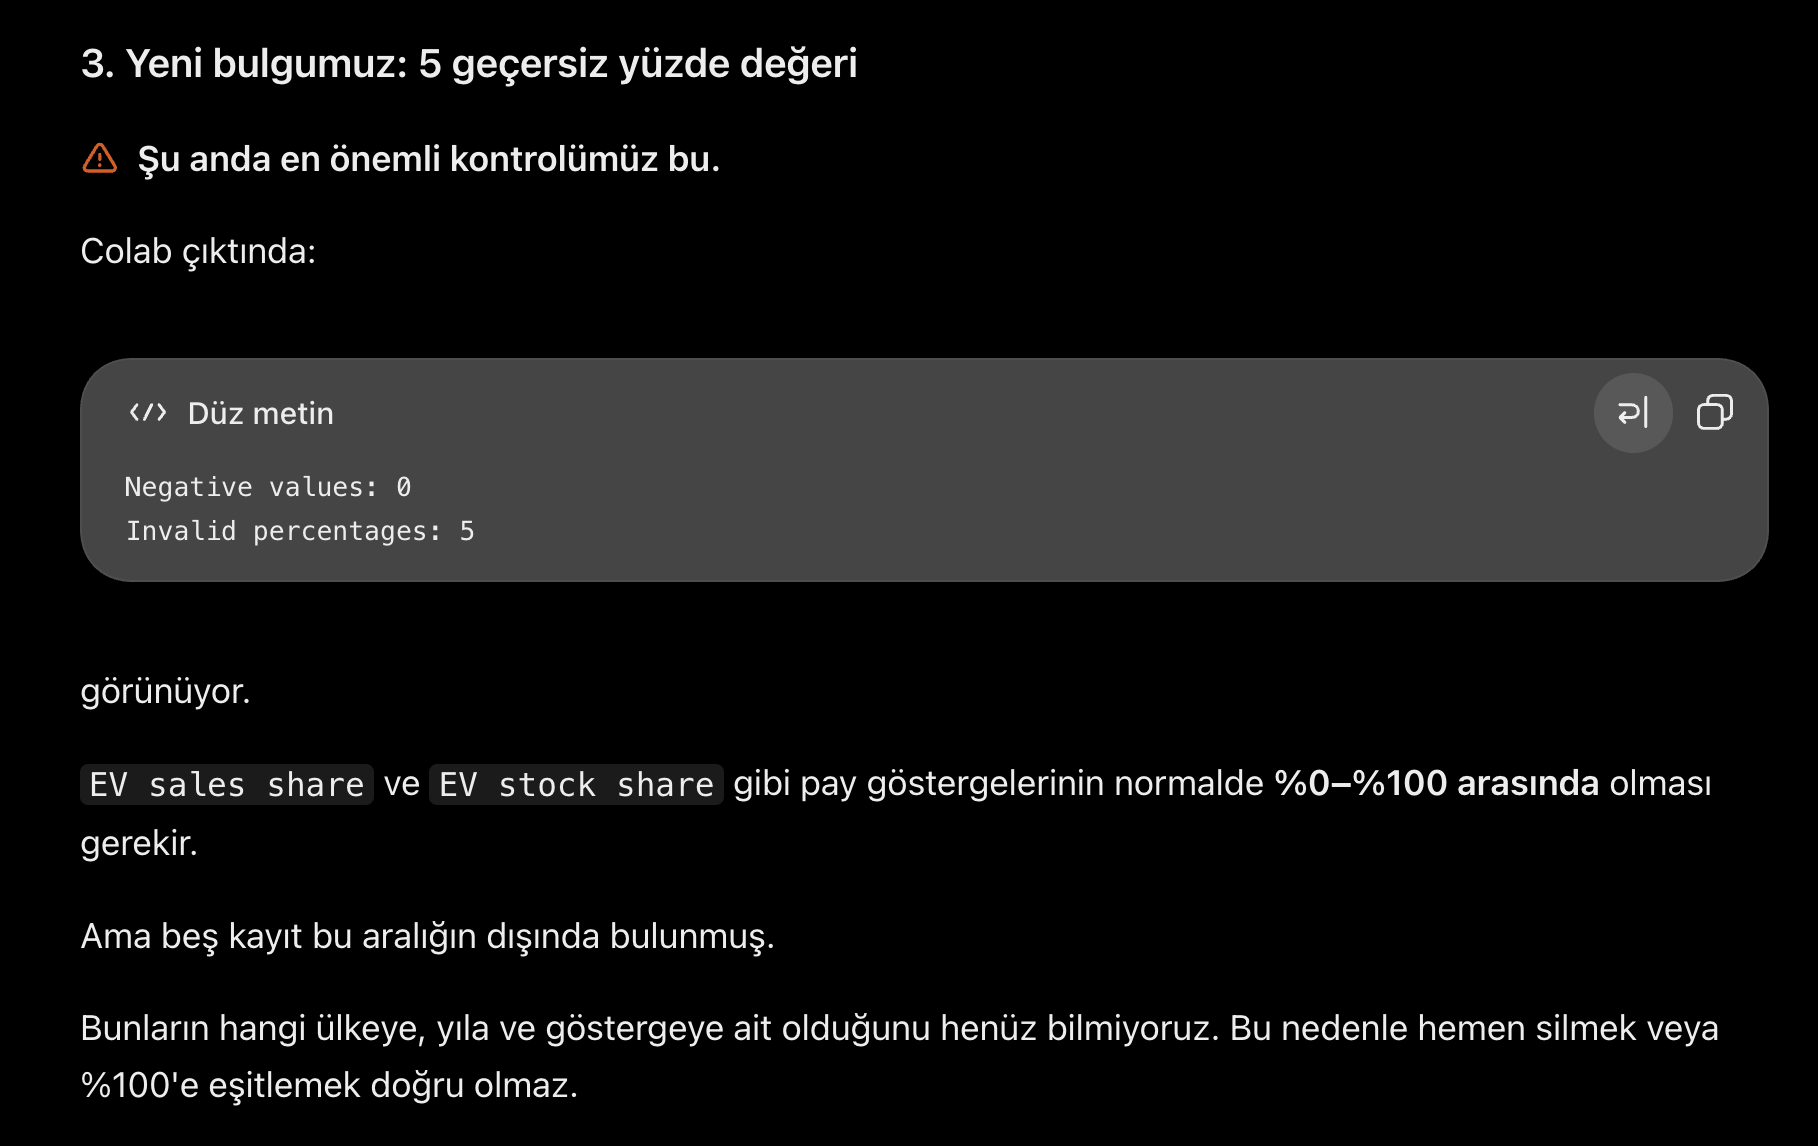

In [28]:
# Yüzde birimindeki kayıtları seç
percentage_data = df_clean[
    df_clean["unit"] == "percent"
]

# 0-100 aralığı dışındaki değerleri bul
invalid_percentages = percentage_data[
    (percentage_data["value"] < 0) |
    (percentage_data["value"] > 100)
]

print("Invalid percentage count:", len(invalid_percentages))

display(
    invalid_percentages[
        [
            "region_country",
            "category",
            "parameter",
            "mode",
            "powertrain",
            "year",
            "value",
            "unit",
            "Aggregate group"
        ]
    ]
)

Invalid percentage count: 5


,region_country,category,parameter,mode,powertrain,year,value,unit,Aggregate group
17899,United Arab Emirates,Historical,EV sales share,Vans,EV,2021,200.0,percent,Other
17900,United Arab Emirates,Historical,EV sales share,Vans,EV,2022,280.0,percent,Other
17901,United Arab Emirates,Historical,EV sales share,Vans,EV,2023,310.0,percent,Other
17902,United Arab Emirates,Historical,EV sales share,Vans,EV,2024,290.0,percent,Other
17903,United Arab Emirates,Historical,EV sales share,Vans,EV,2025,210.0,percent,Other


In [29]:
# Bence bu 5 kaydı
# hemen silmek yerine önce orijinal IEA Excel dosyasında da aynı değerlerin bulunup bulunmadığını kontrol edelim.
check_uae = df[
    (df["region_country"] == "United Arab Emirates") &
    (df["mode"] == "Vans") &
    (df["parameter"] == "EV sales share")
]

display(
    check_uae[
        ["year", "category", "value", "unit"]
    ].sort_values("year")
)

,year,category,value,unit
17898,2020,Historical,5.6,percent
17899,2021,Historical,200.0,percent
17900,2022,Historical,280.0,percent
17901,2023,Historical,310.0,percent
17902,2024,Historical,290.0,percent
17903,2025,Historical,210.0,percent


In [30]:
#Proje raporunda da bu işlemi, “Satış payı tanımına göre
#%100'ü aşan beş kayıt analiz veri setinden çıkarıldı.” şeklinde gerekçelendirebiliriz.

# Temizleme öncesi
print("Rows before:", len(df_clean))

# Geçersiz yüzde kayıtlarını çıkar
df_clean = df_clean[
    ~(
        (df_clean["unit"] == "percent") &
        ((df_clean["value"] < 0) | (df_clean["value"] > 100))
    )
].copy()

df_clean = df_clean.reset_index(drop=True)

# Sonuçları kontrol et
print("Rows after:", len(df_clean))
print("Remaining invalid percentages:",
      len(df_clean[
          (df_clean["unit"] == "percent") &
          (df_clean["value"] > 100)
      ]))

Rows before: 48282
Rows after: 48277
Remaining invalid percentages: 0


# 3. Şimdi Adım 6 — Coğrafi verileri tanıyalım
Bu aşamada hiçbir satır silmeyeceğiz. Önce region_country sütununun hem ülkeleri hem bölgesel toplamları nasıl içerdiğini anlayacağız.

In [31]:
print("Unique region/country values:",
      df_clean["region_country"].nunique())

print("\nAggregate group distribution:")
display(
    df_clean["Aggregate group"].value_counts()
)

print("\nRegions and countries by aggregate group:")

for group in df_clean["Aggregate group"].unique():
    print(f"\n--- {group} ---")

    regions = sorted(
        df_clean.loc[
            df_clean["Aggregate group"] == group,
            "region_country"
        ].unique()
    )

    print(regions)

Unique region/country values: 72

Aggregate group distribution:


,count
Aggregate group,
Other,30631
Projection_country,9846
Projection_region,2955
Other_aggregate,2844
_World,1230
European Union,771



Regions and countries by aggregate group:

--- Other ---
['Argentina', 'Australia', 'Austria', 'Belgium', 'Brazil', 'Bulgaria', 'Cambodia', 'Canada', 'Chile', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Indonesia', 'Ireland', 'Israel', 'Italy', 'Jordan', 'Lao PDR', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Mexico', 'Nepal', 'Netherlands', 'New Zealand', 'Norway', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russia', 'Seychelles', 'Singapore', 'Slovakia', 'Slovenia', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkiye', 'United Arab Emirates', 'United Kingdom', 'Uruguay', 'Uzbekistan', 'Viet Nam']

--- _World ---
['World']

--- Projection_country ---
['China', 'India', 'Japan', 'Korea', 'USA']

--- Projection_region ---
['Europe', 'Latin America', 'Southeast Asia']

--- Other_aggregate ---
['Advanced Economies', 'Africa', 'Asia Pacific', 'Developing

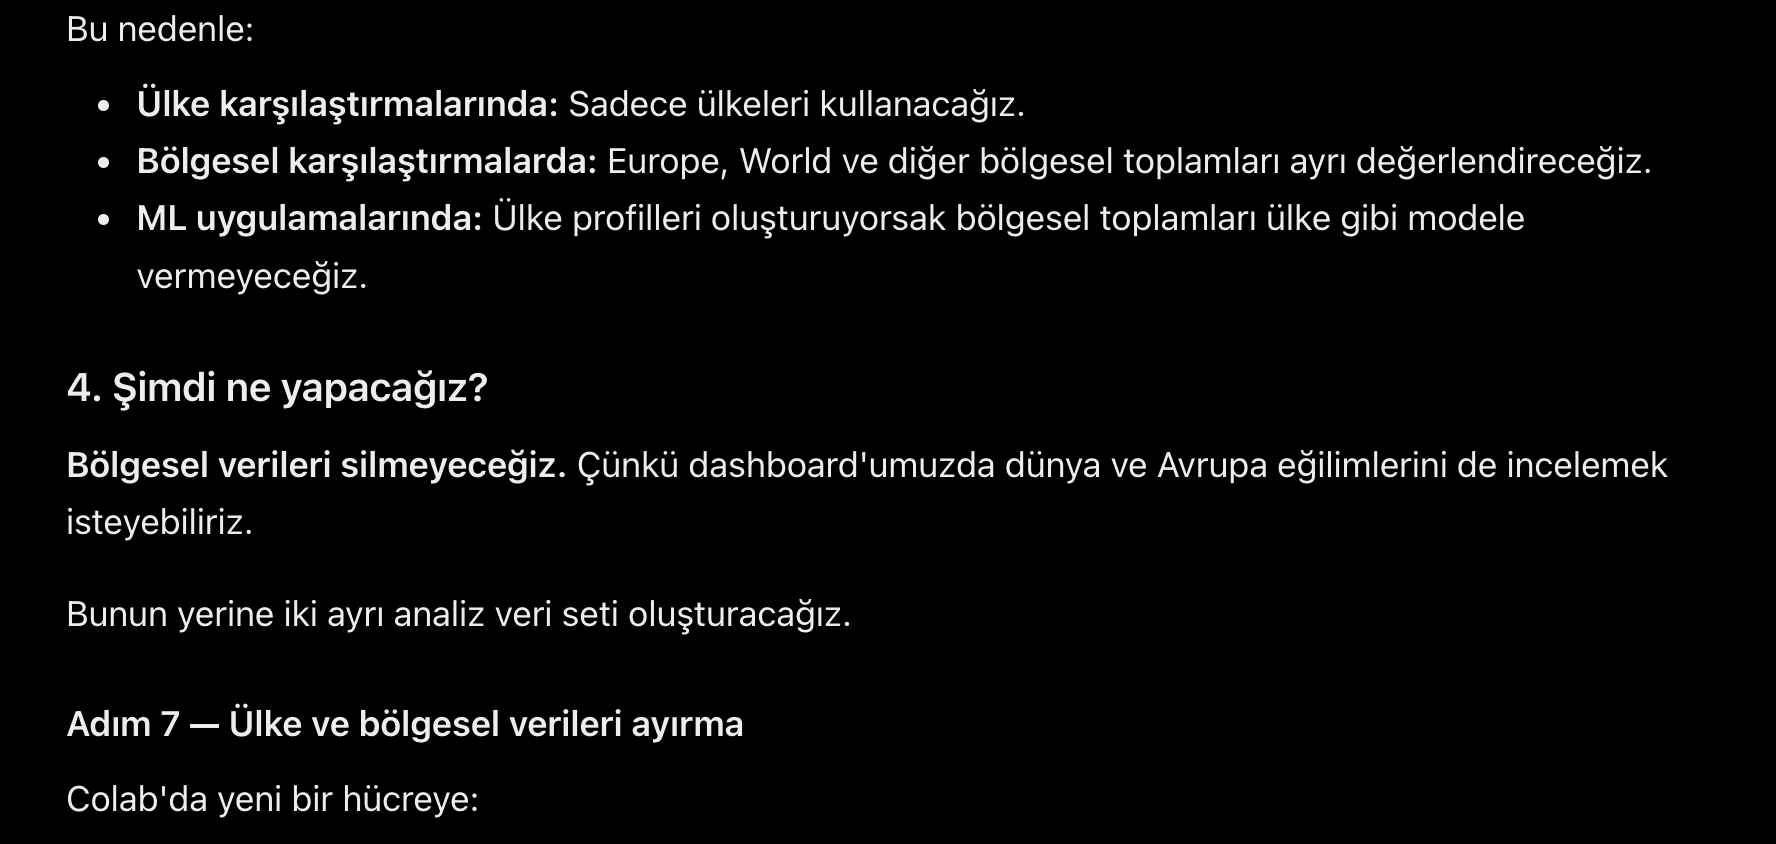

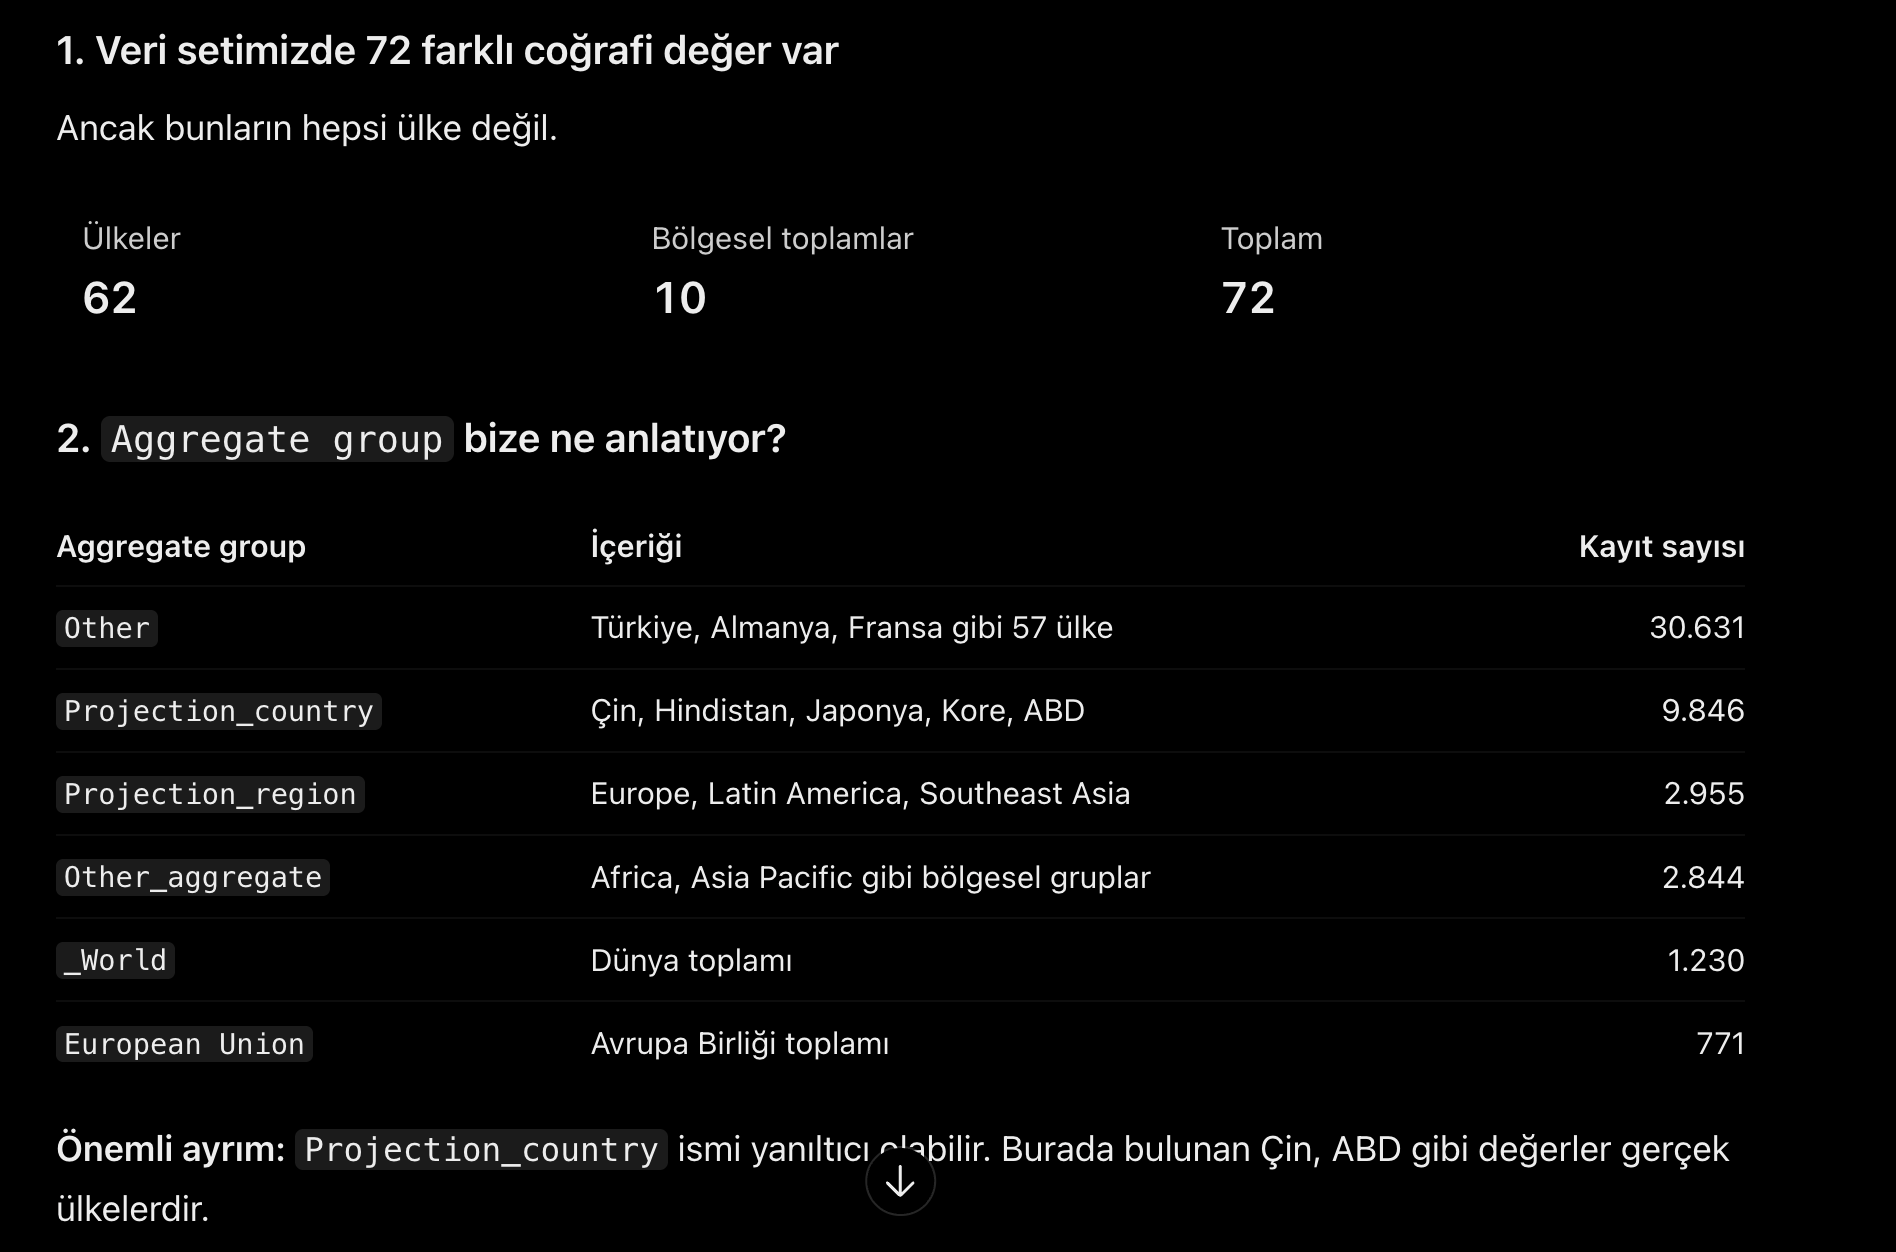

In [32]:
# Ülkelere ait kayıtlar
country_groups = ["Other", "Projection_country"]

df_countries = df_clean[
    df_clean["Aggregate group"].isin(country_groups)
].copy()

# Bölgesel ve dünya toplamları
df_regions = df_clean[
    ~df_clean["Aggregate group"].isin(country_groups)
].copy()

print("Main dataset:", len(df_clean))
print("Country records:", len(df_countries))
print("Regional records:", len(df_regions))

print("\nUnique countries:",
      df_countries["region_country"].nunique())

print("Unique regions:",
      df_regions["region_country"].nunique())

Main dataset: 48277
Country records: 40477
Regional records: 7800

Unique countries: 62
Unique regions: 10


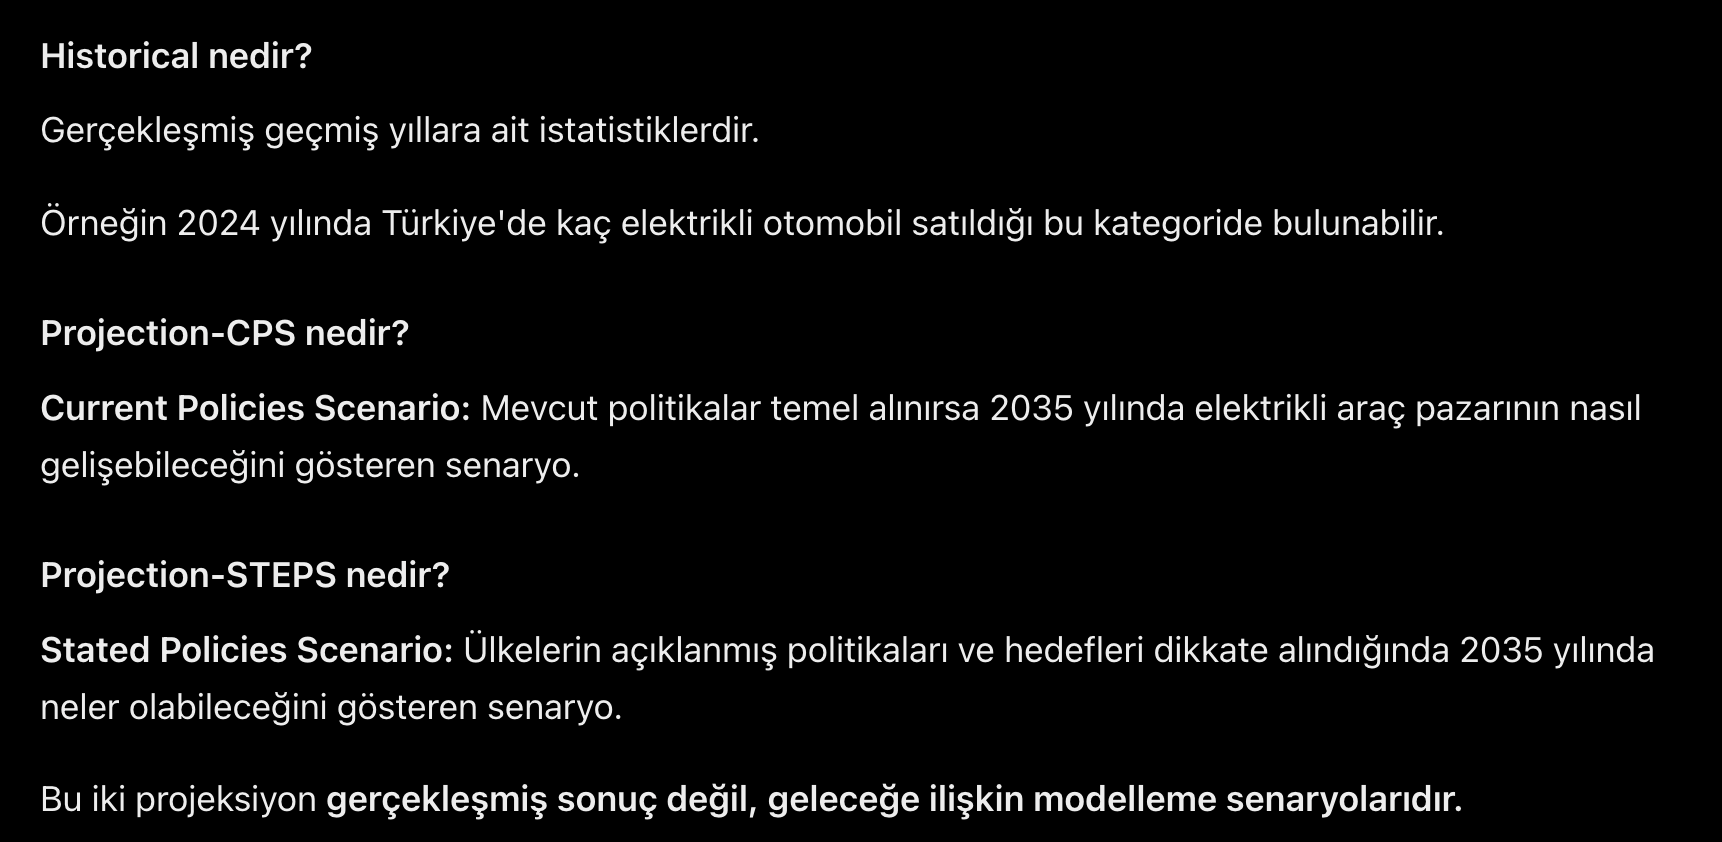

In [33]:
#Hücre 1 — Kategorilerin yıl aralıkları
category_summary = (
    df_clean.groupby("category")
    .agg(
        total_rows=("year", "size"),
        min_year=("year", "min"),
        max_year=("year", "max"),
        unique_years=("year", "nunique")
    )
)

display(category_summary)

,total_rows,min_year,max_year,unique_years
category,,,,
Historical,47016,2010,2025,16
Projection-CPS,621,2035,2035,1
Projection-STEPS,640,2035,2035,1


In [34]:
year_category = pd.crosstab(
    df_clean["year"],
    df_clean["category"]
)

display(year_category)

category,Historical,Projection-CPS,Projection-STEPS
year,,,
2010,1364,0,0
2011,1558,0,0
2012,1959,0,0
2013,2236,0,0
2014,2534,0,0
2015,2968,0,0
2016,3165,0,0
2017,3326,0,0
2018,3670,0,0


In [36]:
# Hücre 1 — 2035 projeksiyonlarının göstergelerini inceleyelim
#Her parameter için CPS ve STEPS senaryolarında kaç kayıt olduğunu gösterecek.
# Yalnızca gelecek projeksiyonlarını seçiyoruz
df_projection = df_clean[
    df_clean["category"].isin([
        "Projection-CPS",
        "Projection-STEPS"
    ])
].copy()

# Hangi göstergeler hangi senaryoda var?
projection_parameters = pd.crosstab(
    df_projection["parameter"],
    df_projection["category"]
)

display(projection_parameters)

category,Projection-CPS,Projection-STEPS
parameter,,
Average capacity per EV,9,9
Average capacity per EVSE,9,9
Battery deployment,45,45
EV charging points,27,27
EV sales,145,156
EV sales share,45,45
EV stock,152,160
EV stock share,45,45
Electric LDVs per charging point,9,9


In [37]:
comparison_keys = [
    "region_country",
    "parameter",
    "mode",
    "powertrain",
    "year",
    "unit",
    "Aggregate group"
]

scenario_coverage = (
    df_projection.groupby(comparison_keys)["category"]
    .nunique()
    .reset_index(name="scenario_count")
)

print("Both scenarios available:",
      (scenario_coverage["scenario_count"] == 2).sum())

print("Only one scenario available:",
      (scenario_coverage["scenario_count"] == 1).sum())

Both scenarios available: 620
Only one scenario available: 21


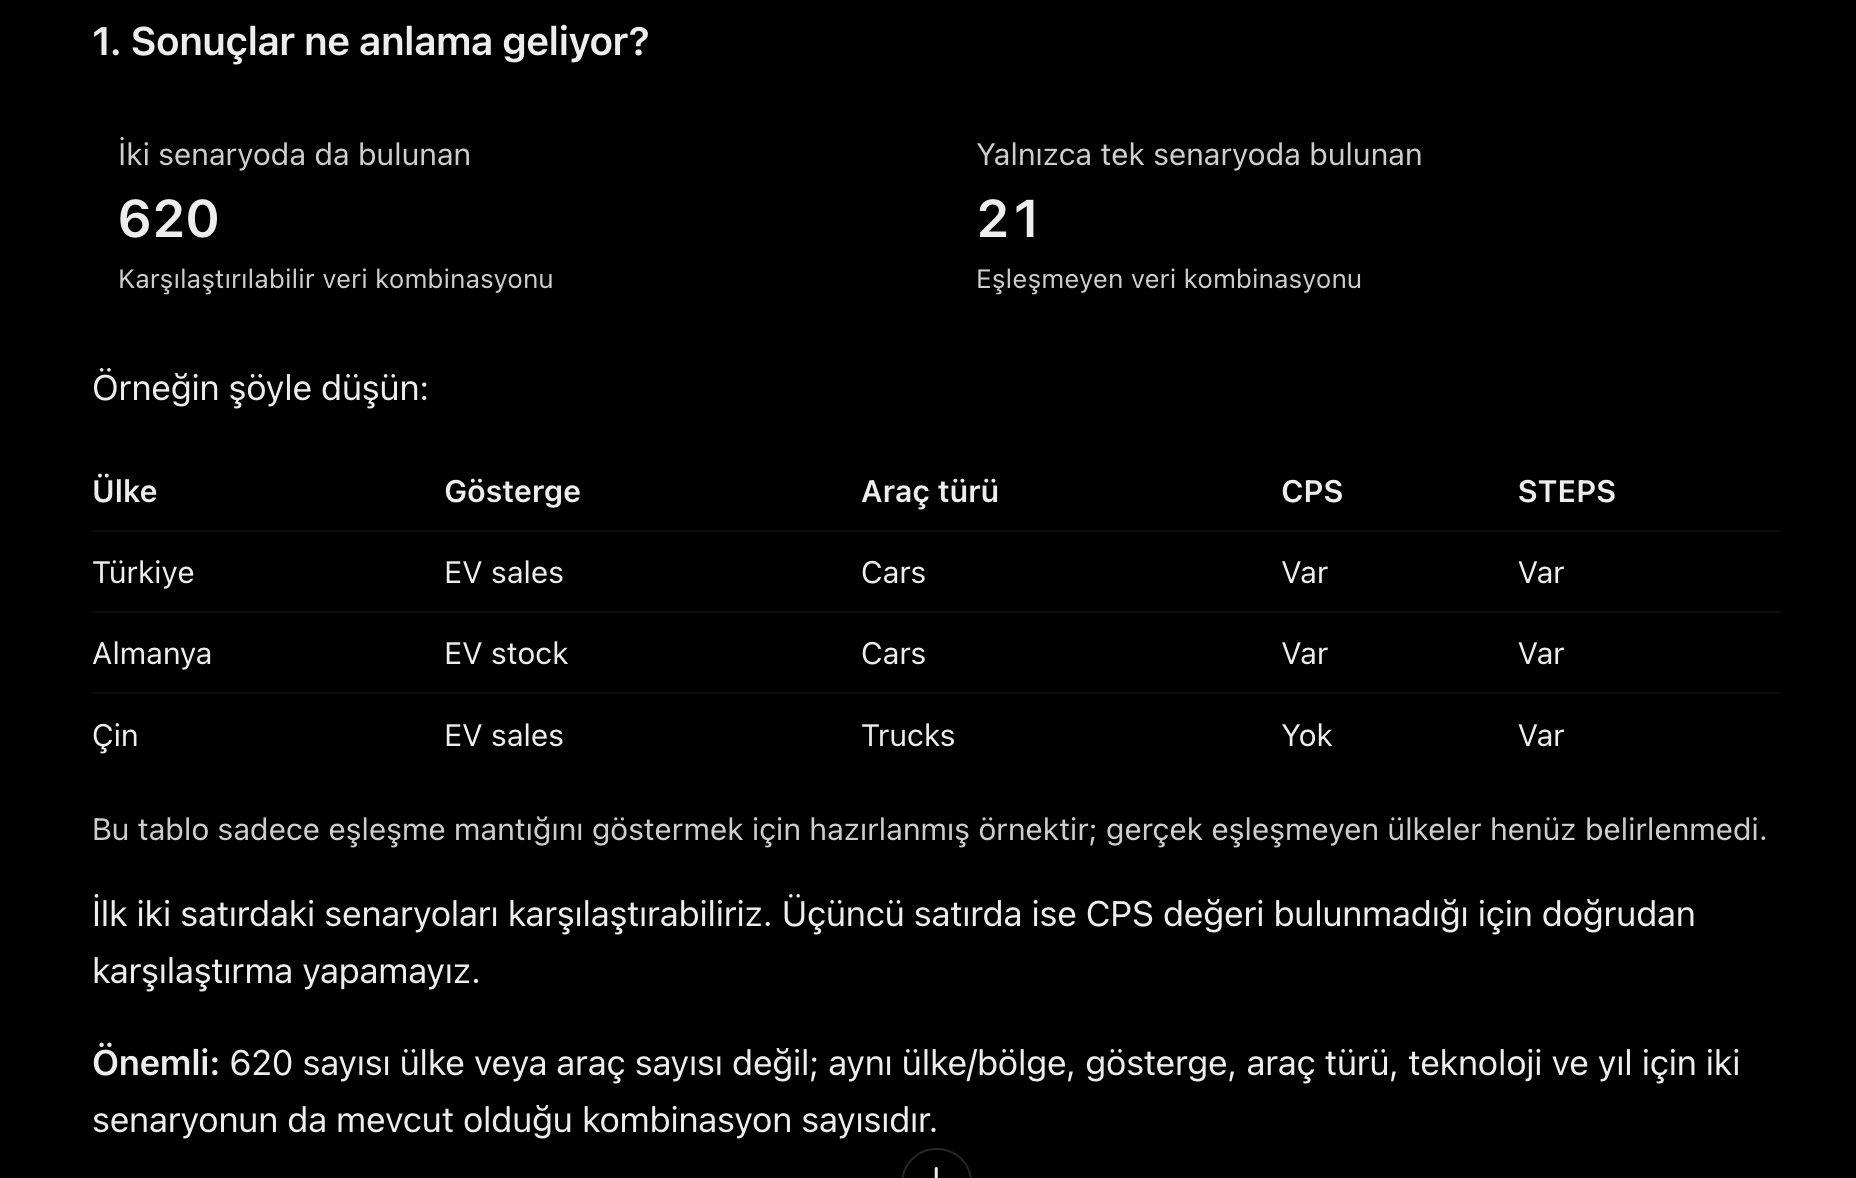

In [38]:
# Yalnızca bir senaryoda bulunan kombinasyonlar
unmatched_keys = scenario_coverage[
    scenario_coverage["scenario_count"] == 1
][comparison_keys]

# Bu kombinasyonların gerçek kayıtlarını getir
unmatched_scenarios = df_projection.merge(
    unmatched_keys,
    on=comparison_keys,
    how="inner"
)

print("Unmatched records:", len(unmatched_scenarios))

print("\nBy scenario:")
print(unmatched_scenarios["category"].value_counts())

print("\nBy parameter:")
print(unmatched_scenarios["parameter"].value_counts())

display(
    unmatched_scenarios[
        [
            "region_country",
            "category",
            "parameter",
            "mode",
            "powertrain",
            "value"
        ]
    ].sort_values(["parameter", "region_country"])
)

Unmatched records: 21

By scenario:
category
Projection-STEPS    20
Projection-CPS       1
Name: count, dtype: int64

By parameter:
parameter
EV sales    11
EV stock    10
Name: count, dtype: int64


,region_country,category,parameter,mode,powertrain,value
0,India,Projection-STEPS,EV sales,Trucks,FCEV,220.0
1,India,Projection-STEPS,EV sales,Trucks,PHEV,220.0
8,Japan,Projection-STEPS,EV sales,Buses,PHEV,7.9
9,Japan,Projection-STEPS,EV sales,Trucks,FCEV,520.0
10,Japan,Projection-STEPS,EV sales,Trucks,PHEV,3400.0
12,Korea,Projection-STEPS,EV sales,Trucks,PHEV,810.0
4,Latin America,Projection-STEPS,EV sales,Trucks,FCEV,140.0
5,Latin America,Projection-STEPS,EV sales,Trucks,PHEV,350.0
15,Southeast Asia,Projection-STEPS,EV sales,Trucks,FCEV,12.0
16,Southeast Asia,Projection-STEPS,EV sales,Trucks,PHEV,1100.0


### 4. Şimdi karşılaştırma veri setini oluşturalım
Colab'da yeni bir hücreye:

In [39]:
# CPS ve STEPS değerlerini yan yana getir
df_scenario_comparison = df_projection.pivot(
    index=comparison_keys,
    columns="category",
    values="value"
).reset_index()

# Yalnızca iki senaryoda da bulunan kayıtları seç
df_scenario_comparison = (
    df_scenario_comparison.dropna(
        subset=["Projection-CPS", "Projection-STEPS"]
    ).copy()
)

# STEPS ile CPS arasındaki fark
df_scenario_comparison["difference"] = (
    df_scenario_comparison["Projection-STEPS"]
    - df_scenario_comparison["Projection-CPS"]
)

print(
    "Comparable combinations:",
    len(df_scenario_comparison)
)

display(df_scenario_comparison.head(10))

Comparable combinations: 620


category,region_country,parameter,mode,powertrain,year,unit,Aggregate group,Projection-CPS,Projection-STEPS,difference
0,China,Average capacity per EV,EV,EV,2035,kW/EV,Projection_country,4.8,4.8,0.0
1,China,Average capacity per EVSE,EV,EV,2035,kW/EVSE,Projection_country,71.0,71.0,0.0
2,China,Battery deployment,2 and 3 wheelers,EV,2035,GWh,Projection_country,74.0,74.0,0.0
3,China,Battery deployment,Buses,EV,2035,GWh,Projection_country,30.0,30.0,0.0
4,China,Battery deployment,Cars,EV,2035,GWh,Projection_country,1600.0,1600.0,0.0
5,China,Battery deployment,Trucks,EV,2035,GWh,Projection_country,340.0,340.0,0.0
6,China,Battery deployment,Vans,EV,2035,GWh,Projection_country,49.0,49.0,0.0
7,China,EV charging points,EVSE,Publicly available fast,2035,charging points,Projection_country,5400000.0,5400000.0,0.0
8,China,EV charging points,EVSE,Publicly available slow,2035,charging points,Projection_country,9000000.0,9000000.0,0.0
9,China,EV charging points,EVSE,Publicly available ultra-fast,2035,charging points,Projection_country,3700000.0,3700000.0,0.0


In [40]:
import numpy as np

# İki senaryo arasındaki farkları kontrol et
different = ~np.isclose(
    df_scenario_comparison["Projection-CPS"],
    df_scenario_comparison["Projection-STEPS"]
)

print("Total comparisons:", len(df_scenario_comparison))

print("Same predictions:", (~different).sum())

print("Different predictions:", different.sum())

print("\nDifferences by parameter:")

display(
    df_scenario_comparison.assign(
        is_different=different
    ).groupby("parameter")["is_different"]
     .agg(["size", "sum"])
     .rename(columns={
         "size": "Total comparisons",
         "sum": "Different predictions"
     })
)

Total comparisons: 620
Same predictions: 82
Different predictions: 538

Differences by parameter:


,Total comparisons,Different predictions
parameter,,
Average capacity per EV,9,5
Average capacity per EVSE,9,6
Battery deployment,45,39
EV charging points,27,24
EV sales,145,127
EV sales share,45,40
EV stock,151,128
EV stock share,45,40
Electric LDVs per charging point,9,6


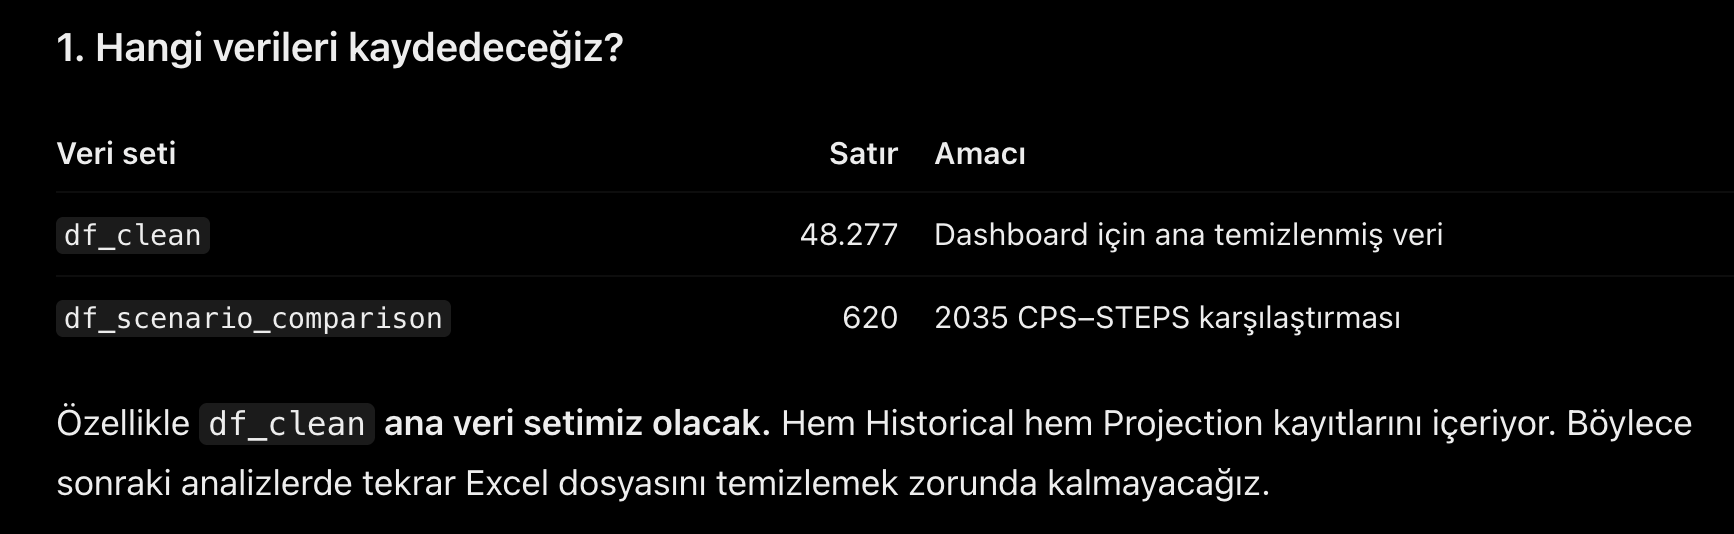

In [41]:
# Ana temizlenmiş veri setini kaydet
df_clean.to_csv(
    "global_ev_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset saved successfully!")
print("Shape:", df_clean.shape)

Dataset saved successfully!
Shape: (48277, 9)


In [42]:
df_scenario_comparison.to_csv(
    "ev_2035_scenario_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Scenario comparison saved!")
print("Shape:", df_scenario_comparison.shape)

Scenario comparison saved!
Shape: (620, 10)


In [43]:
from google.colab import files

files.download("global_ev_cleaned.csv")
files.download("ev_2035_scenario_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

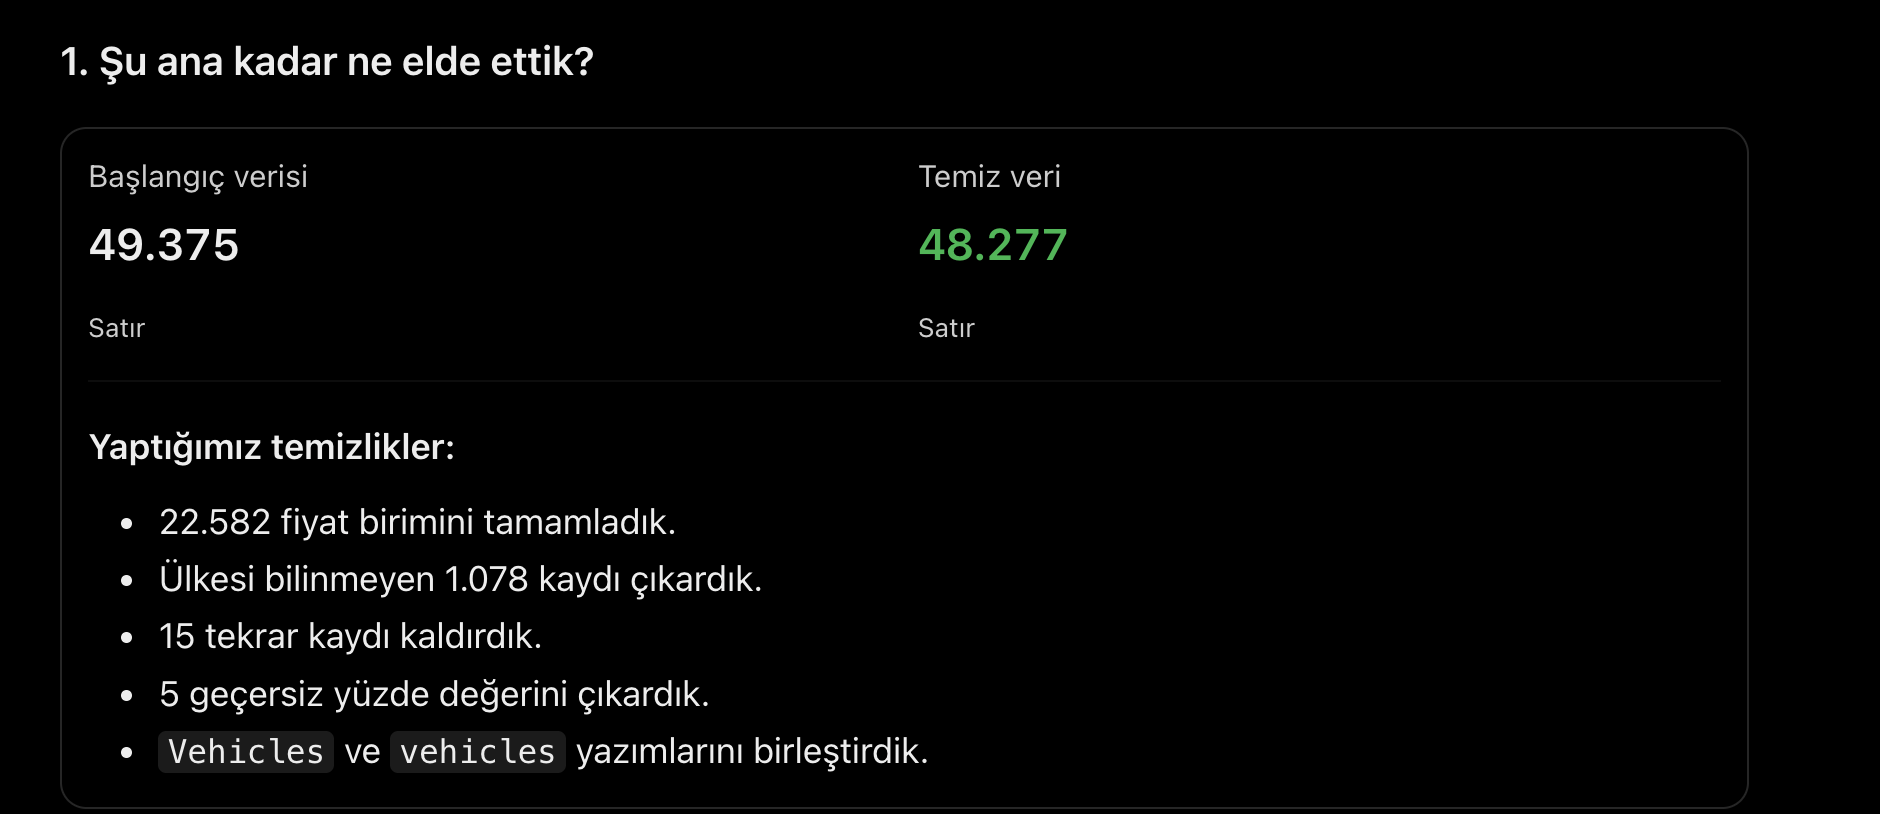

In [44]:
print("FINAL DATA QUALITY CHECK")
print("-" * 50)

# 1. Genel durum
print("Total rows:", len(df_clean))
print("Total columns:", len(df_clean.columns))

# 2. Eksik değerler
print("\nMissing values:")
print(df_clean.isna().sum())

# 3. Tekrarlanan kayıtlar
print("\nDuplicate rows:", df_clean.duplicated().sum())

# 4. Sıfır ve negatif değerler
print("\nZero values:", (df_clean["value"] == 0).sum())
print("Negative values:", (df_clean["value"] < 0).sum())

# 5. Geçersiz yüzdeler
invalid_percent = df_clean[
    (df_clean["unit"] == "percent") &
    (
        (df_clean["value"] < 0) |
        (df_clean["value"] > 100)
    )
]

print("Invalid percentages:", len(invalid_percent))

# 6. Historical / Projection dağılımı
print("\nData categories:")
print(df_clean["category"].value_counts())

# 7. Ülke ve bölge verilerinin dağılımı
print("\nGeographical groups:")
print(df_clean["Aggregate group"].value_counts())

# 8. Her göstergenin değer aralığı
print("\nValue ranges by parameter:")

parameter_ranges = (
    df_clean.groupby(["parameter", "unit"])
    .agg(
        Count=("value", "size"),
        Minimum=("value", "min"),
        Median=("value", "median"),
        Maximum=("value", "max"),
        Zero_Count=("value", lambda x: (x == 0).sum())
    )
    .reset_index()
)

display(parameter_ranges)

FINAL DATA QUALITY CHECK
--------------------------------------------------
Total rows: 48277
Total columns: 9

Missing values:
region_country     0
category           0
parameter          0
mode               0
powertrain         0
year               0
unit               0
value              0
Aggregate group    0
dtype: int64

Duplicate rows: 0

Zero values: 0
Negative values: 0
Invalid percentages: 0

Data categories:
category
Historical          47016
Projection-STEPS      640
Projection-CPS        621
Name: count, dtype: int64

Geographical groups:
Aggregate group
Other                 30631
Projection_country     9846
Projection_region      2955
Other_aggregate        2844
_World                 1230
European Union          771
Name: count, dtype: int64

Value ranges by parameter:


,parameter,unit,Count,Minimum,Median,Maximum,Zero_Count
0,Average capacity per EV,kW/EV,596,0.023000,2.3000,43.0,0
1,Average capacity per EVSE,kW/EVSE,597,15.000000,24.0000,150.0,0
2,Battery deployment,GWh,546,0.000130,0.7400,3700.0,0
3,EV charging points,charging points,1457,1.000000,1600.0000,15000000.0,0
4,EV sales,Vehicles,7647,0.001000,900.0000,55000000.0,0
5,EV sales share,percent,2828,0.000032,0.9850,97.0,0
6,EV stock,Vehicles,7891,0.980000,2100.0000,470000000.0,0
7,EV stock share,percent,2777,0.000009,0.1900,73.0,0
8,Electric LDVs per charging point,Vehicles,596,0.360000,11.0000,640.0,0
9,Electricity demand,GWh,594,0.004200,235.0000,940000.0,0


In [45]:
df_clean.loc[
    df_clean["parameter"] == "Electric LDVs per charging point",
    "unit"
] = "vehicles"

In [46]:
display(
    df_clean[
        ["parameter", "unit"]
    ].drop_duplicates().sort_values("parameter")
)

,parameter,unit
19358,Average capacity per EV,kW/EV
19806,Average capacity per EVSE,kW/EVSE
7115,Battery deployment,GWh
0,EV charging points,charging points
915,EV sales,Vehicles
13053,EV sales share,percent
3514,EV stock,Vehicles
13069,EV stock share,percent
18910,Electric LDVs per charging point,vehicles
6879,Electricity demand,GWh


In [47]:
print("Dataset shape:", df_clean.shape)

print("\nUnit values:")
print(df_clean["unit"].value_counts())

print("\nMissing values:", df_clean.isna().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Dataset shape: (48277, 9)

Unit values:
unit
2025 USD                              21504
Vehicles                              15538
percent                                5605
charging points                        1457
GWh                                    1140
Million litres gasoline equivalent      622
Million barrels per day                 622
kW/EVSE                                 597
kW/EV                                   596
vehicles                                596
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0


### Son kararımız: Orijinal birim yazımlarını koruyoruz. Analiz ve grafiklerde ise sadece unit değil, her zaman parameter bilgisini de dikkate alıyoruz.

In [48]:
df_clean.to_csv(
    "global_ev_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

In [49]:
from google.colab import files

files.download("global_ev_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
# Güncel temiz veriden projeksiyonları seç
df_projection = df_clean[
    df_clean["category"].isin([
        "Projection-CPS",
        "Projection-STEPS"
    ])
].copy()

# Aynı ölçümü tanımlayan sütunlar
comparison_keys = [
    "region_country",
    "parameter",
    "mode",
    "powertrain",
    "year",
    "unit",
    "Aggregate group"
]

# CPS ve STEPS değerlerini yan yana getir
df_scenario_comparison = df_projection.pivot(
    index=comparison_keys,
    columns="category",
    values="value"
).reset_index()

# Yalnızca eşleşen senaryoları al
df_scenario_comparison = (
    df_scenario_comparison.dropna(
        subset=["Projection-CPS", "Projection-STEPS"]
    ).copy()
)

# Senaryolar arasındaki fark
df_scenario_comparison["difference"] = (
    df_scenario_comparison["Projection-STEPS"]
    - df_scenario_comparison["Projection-CPS"]
)

print("Comparable combinations:", len(df_scenario_comparison))

display(df_scenario_comparison.head())

Comparable combinations: 620


category,region_country,parameter,mode,powertrain,year,unit,Aggregate group,Projection-CPS,Projection-STEPS,difference
0,China,Average capacity per EV,EV,EV,2035,kW/EV,Projection_country,4.8,4.8,0.0
1,China,Average capacity per EVSE,EV,EV,2035,kW/EVSE,Projection_country,71.0,71.0,0.0
2,China,Battery deployment,2 and 3 wheelers,EV,2035,GWh,Projection_country,74.0,74.0,0.0
3,China,Battery deployment,Buses,EV,2035,GWh,Projection_country,30.0,30.0,0.0
4,China,Battery deployment,Cars,EV,2035,GWh,Projection_country,1600.0,1600.0,0.0


In [51]:
# İlgili göstergenin birimi doğru mu?
check = df_scenario_comparison[
    df_scenario_comparison["parameter"] ==
    "Electric LDVs per charging point"
]

display(
    check[
        ["region_country", "parameter", "unit"]
    ]
)

category,region_country,parameter,unit
55,China,Electric LDVs per charging point,vehicles
127,Europe,Electric LDVs per charging point,vehicles
196,India,Electric LDVs per charging point,vehicles
268,Japan,Electric LDVs per charging point,vehicles
340,Korea,Electric LDVs per charging point,vehicles
411,Latin America,Electric LDVs per charging point,vehicles
482,Southeast Asia,Electric LDVs per charging point,vehicles
553,USA,Electric LDVs per charging point,vehicles
625,World,Electric LDVs per charging point,vehicles


In [52]:
df_clean.to_csv(
    "global_ev_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

df_scenario_comparison.to_csv(
    "ev_2035_scenario_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

from google.colab import files

files.download("global_ev_cleaned.csv")
files.download("ev_2035_scenario_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
# Aynı ölçümü tanımlayan sütunlar
measurement_keys = [
    "region_country",
    "category",
    "parameter",
    "mode",
    "powertrain",
    "year"
]

# Ölçüm anahtarlarının tekrar edip etmediğini kontrol et
key_check = (
    df_clean.groupby(measurement_keys, dropna=False)
    .agg(
        record_count=("value", "size"),
        unique_values=("value", "nunique"),
        unique_units=("unit", "nunique")
    )
    .reset_index()
)

# Aynı ölçüm için birden fazla kayıt
duplicate_keys = key_check[
    key_check["record_count"] > 1
]

print("Total measurement combinations:", len(key_check))
print("Repeated measurement combinations:", len(duplicate_keys))

print(
    "Conflicting values:",
    (duplicate_keys["unique_values"] > 1).sum()
)

print(
    "Conflicting units:",
    (duplicate_keys["unique_units"] > 1).sum()
)

display(duplicate_keys.head(20))

Total measurement combinations: 48277
Repeated measurement combinations: 0
Conflicting values: 0
Conflicting units: 0


,region_country,category,parameter,mode,powertrain,year,record_count,unique_values,unique_units


In [54]:
import numpy as np
import pandas as pd

# Adet belirten göstergeler
count_parameters = [
    "EV sales",
    "EV stock",
    "EV charging points"
]

count_data = df_clean[
    df_clean["parameter"].isin(count_parameters)
].copy()

# Tam sayı olmayan değerleri işaretle
count_data["fractional_value"] = ~np.isclose(
    count_data["value"],
    np.round(count_data["value"]),
    atol=1e-8,
    rtol=0
)

# Gösterge bazında özet
fractional_summary = (
    count_data.groupby("parameter")
    .agg(
        total_records=("value", "size"),
        fractional_records=("fractional_value", "sum"),
        min_value=("value", "min"),
        max_value=("value", "max")
    )
)

fractional_summary["fractional_percentage"] = (
    fractional_summary["fractional_records"] /
    fractional_summary["total_records"] * 100
).round(2)

display(fractional_summary)

print("\nExamples of fractional values:")

display(
    count_data[
        count_data["fractional_value"]
    ][
        [
            "region_country",
            "category",
            "parameter",
            "mode",
            "powertrain",
            "year",
            "value"
        ]
    ].sort_values("value").head(20)
)

,total_records,fractional_records,min_value,max_value,fractional_percentage
parameter,,,,,
EV charging points,1457,1,1.000,15000000.0,0.07
EV sales,7647,8,0.001,55000000.0,0.10
EV stock,7891,9,0.980,470000000.0,0.11



Examples of fractional values:


,region_country,category,parameter,mode,powertrain,year,value
1390,Israel,Historical,EV sales,Buses,BEV,2013,0.001
45213,Israel,Historical,EV sales,Buses,EV,2013,0.001
11933,Developing Economies excl. China,Historical,EV stock,Trucks,FCEV,2025,0.980
13034,Middle East and Caspian,Historical,EV stock,Trucks,FCEV,2025,0.980
5002,Netherlands,Historical,EV stock,Cars,FCEV,2014,2.200
2235,Netherlands,Historical,EV sales,Cars,FCEV,2014,2.200
12985,Middle East and Caspian,Historical,EV stock,Buses,FCEV,2023,2.900
9490,Latin America,Projection-STEPS,EV stock,Cars,FCEV,2035,3.900
9444,Latin America,Projection-CPS,EV stock,Cars,FCEV,2035,3.900
9803,Japan,Projection-CPS,EV stock,Trucks,FCEV,2035,4.300


In [55]:
fractional_records = count_data[
    count_data["fractional_value"]
].copy()

print("Fractional records:", len(fractional_records))

print("\nBy category:")
display(
    fractional_records["category"].value_counts()
)

print("\nValues smaller than 1:")
display(
    fractional_records[
        fractional_records["value"] < 1
    ][
        [
            "region_country",
            "category",
            "parameter",
            "mode",
            "powertrain",
            "year",
            "value"
        ]
    ]
)

print("\nBy aggregate group:")
display(
    fractional_records["Aggregate group"].value_counts()
)

Fractional records: 18

By category:


,count
category,
Historical,12
Projection-CPS,4
Projection-STEPS,2



Values smaller than 1:


,region_country,category,parameter,mode,powertrain,year,value
1390,Israel,Historical,EV sales,Buses,BEV,2013,0.001
11933,Developing Economies excl. China,Historical,EV stock,Trucks,FCEV,2025,0.980
13034,Middle East and Caspian,Historical,EV stock,Trucks,FCEV,2025,0.980
45213,Israel,Historical,EV sales,Buses,EV,2013,0.001



By aggregate group:


,count
Aggregate group,
Other,7
Other_aggregate,5
Projection_region,4
Projection_country,2


### 3. Şimdi sıradaki kontrolümüz: Fiyatlarda olağan dışı değerler
Önceki analizimizde price_p100_2025USD için maksimum 5.000.000 USD bulmuştuk.

Bu değer oldukça yüksek. Fakat maksimum fiyat olması nedeniyle otomatik olarak yanlış kabul edemeyiz.

Hangi ülke, yıl ve araç grubuna ait olduğunu inceleyelim.

In [56]:
# Yalnızca fiyat kayıtlarını seç
price_data = df_clean[
    df_clean["parameter"].str.startswith("price_")
].copy()

# En yüksek 10 fiyat kaydını göster
top_prices = price_data.nlargest(10, "value")

display(
    top_prices[
        [
            "region_country",
            "category",
            "parameter",
            "mode",
            "powertrain",
            "year",
            "value",
            "unit"
        ]
    ]
)

,region_country,category,parameter,mode,powertrain,year,value,unit
26024,USA,Historical,price_p100_2025USD,Large car,ICEV,2025,5000000.0,2025 USD
26629,USA,Historical,price_p100_2025USD,All cars,ICEV,2025,5000000.0,2025 USD
26842,USA,Historical,price_p100_2025USD,All cars,ALL,2025,5000000.0,2025 USD
25375,USA,Historical,price_p100_2025USD,Large car,ICEV,2021,4900000.0,2025 USD
26478,USA,Historical,price_p100_2025USD,All cars,ICEV,2021,4900000.0,2025 USD
26796,USA,Historical,price_p100_2025USD,All cars,ALL,2021,4900000.0,2025 USD
25360,United Kingdom,Historical,price_p100_2025USD,Large car,ICEV,2021,4800000.0,2025 USD
26474,United Kingdom,Historical,price_p100_2025USD,All cars,ICEV,2021,4800000.0,2025 USD
26795,United Kingdom,Historical,price_p100_2025USD,All cars,ALL,2021,4800000.0,2025 USD
25292,Italy,Historical,price_p100_2025USD,Large car,ICEV,2021,4700000.0,2025 USD


ABD'de 2025 yılı Large car–ICEV kategorisinde maksimum fiyat 5 milyon USD iken medyan fiyat 62 bin USD'dir. Bu yüksek değer ileri inceleme gerektiren olası bir aykırı değerdir.

Kısacası: Şu an bulduğumuz şey kesin bir veri hatası değil, fiyat dağılımında dikkat çekici bir uç değer. EDA sırasında bu farkı analiz edebiliriz.

In [57]:
price_check = df_clean[
    (df_clean["region_country"] == "USA") &
    (df_clean["year"] == 2025) &
    (df_clean["mode"] == "Large car") &
    (df_clean["powertrain"] == "ICEV") &
    (df_clean["parameter"].str.startswith("price_"))
]

display(
    price_check[
        ["parameter", "value", "unit"]
    ].sort_values("value")
)

,parameter,value,unit
22952,price_p0_2025USD,27000.0,2025 USD
29096,price_p25_2025USD,47000.0,2025 USD
32168,price_p50_2025USD,62000.0,2025 USD
41384,price_mean_2025USD,78000.0,2025 USD
35240,price_p75_2025USD,91000.0,2025 USD
38312,price_p95_2025USD,150000.0,2025 USD
26024,price_p100_2025USD,5000000.0,2025 USD


### Adım — Coğrafi grubu doğrulama
Amacımız, ABD'deki bu fiyatın bir ülke verisi mi yoksa bölgesel toplam mı olduğunu kesinleştirmek

In [58]:
price_location_check = df_clean[
    (df_clean["region_country"] == "USA") &
    (df_clean["year"] == 2025) &
    (df_clean["parameter"] == "price_p100_2025USD") &
    (df_clean["mode"] == "Large car") &
    (df_clean["powertrain"] == "ICEV")
]

display(
    price_location_check[
        [
            "region_country",
            "category",
            "parameter",
            "mode",
            "powertrain",
            "year",
            "value",
            "unit",
            "Aggregate group"
        ]
    ]
)

,region_country,category,parameter,mode,powertrain,year,value,unit,Aggregate group
26024,USA,Historical,price_p100_2025USD,Large car,ICEV,2025,5000000.0,2025 USD,Projection_country


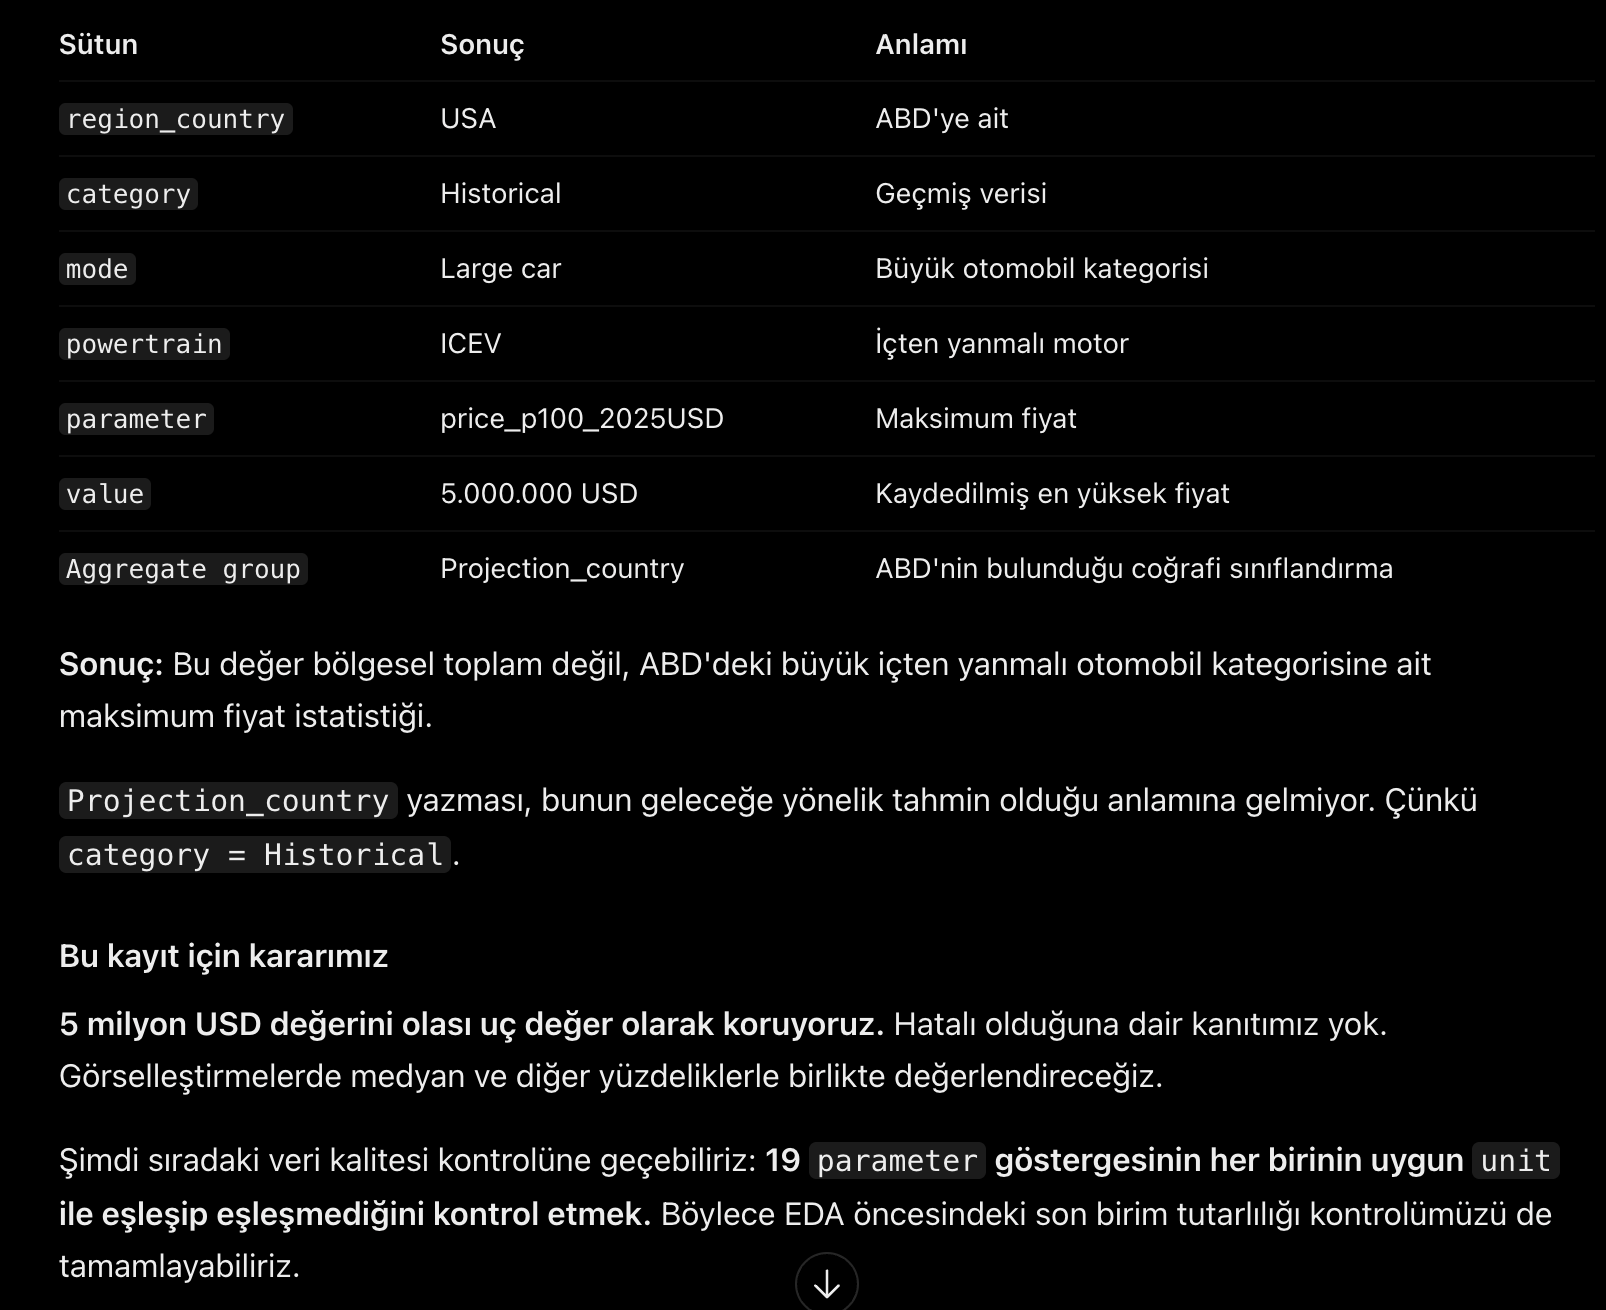

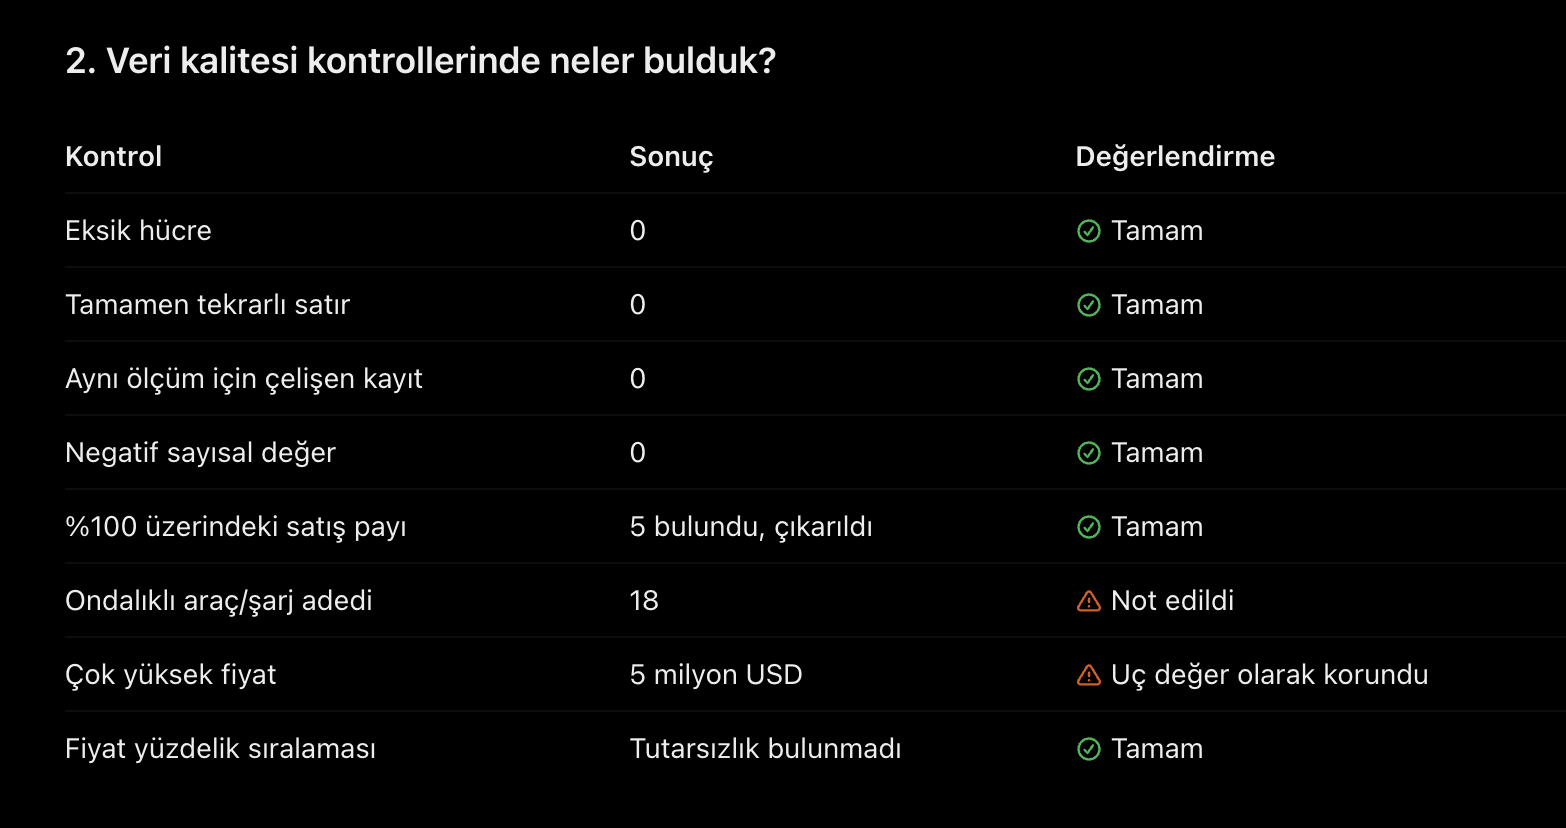

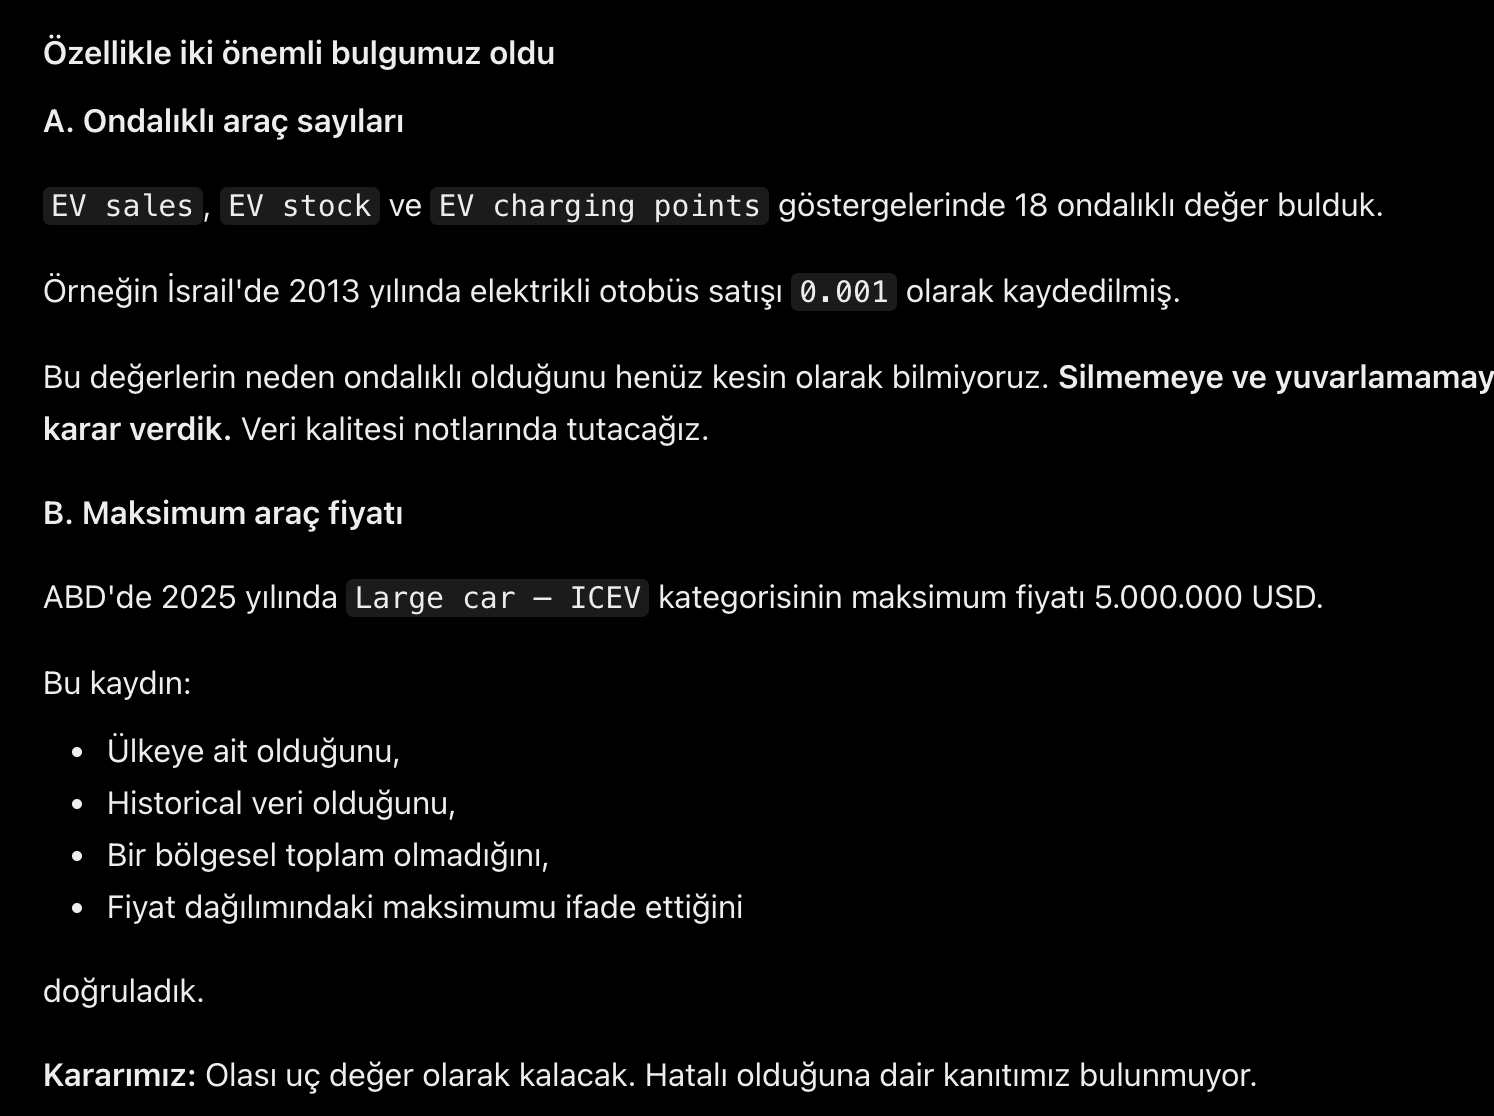

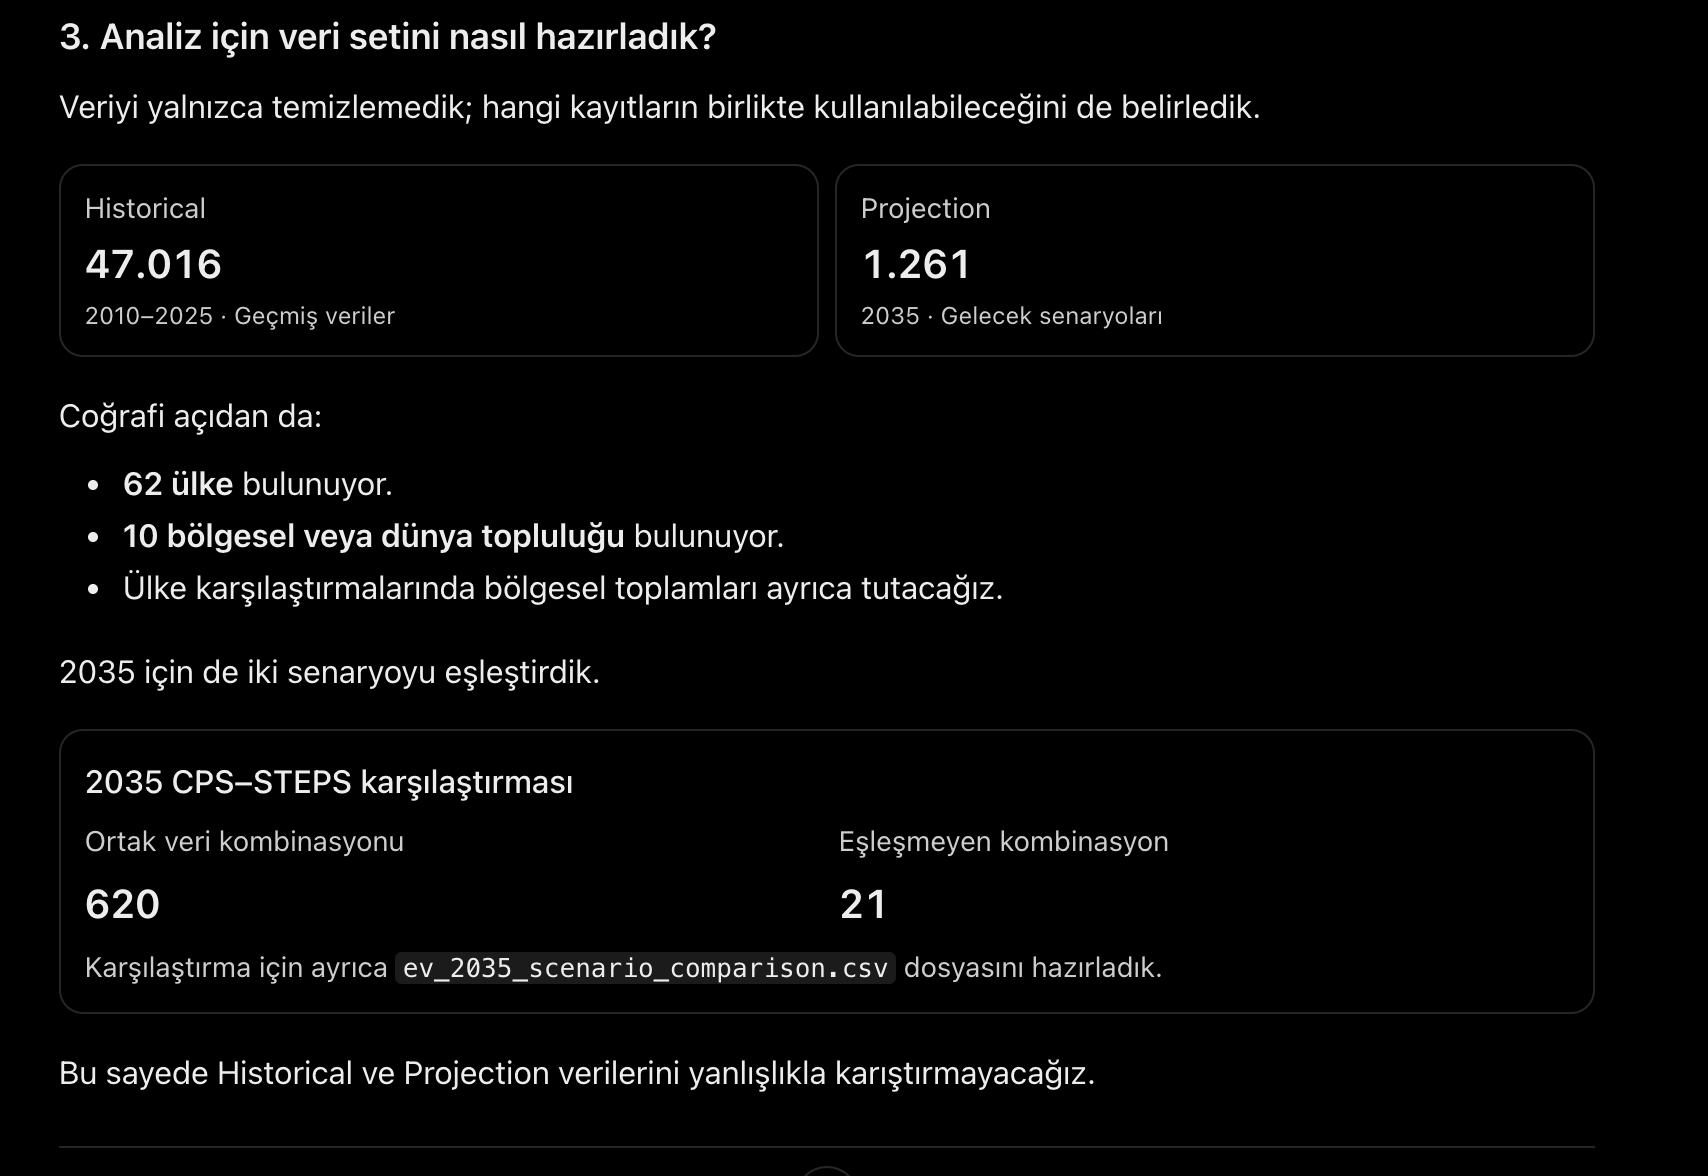

### Evet, son bir önemli kontrol öneriyorum: parameter ile unit eşleşmesi.

Çünkü veri setimizde 19 farklı gösterge var ve aynı value sütununda araç sayısı, yüzde, dolar ve enerji değerleri bulunuyor.

In [59]:
unit_consistency = (
    df_clean.groupby("parameter")
    .agg(
        unique_unit_count=("unit", "nunique"),
        units=("unit", lambda x: ", ".join(sorted(x.unique()))),
        records=("unit", "size")
    )
    .reset_index()
)

display(unit_consistency)

print(
    "Parameters with multiple units:",
    (unit_consistency["unique_unit_count"] > 1).sum()
)

,parameter,unique_unit_count,units,records
0,Average capacity per EV,1,kW/EV,596
1,Average capacity per EVSE,1,kW/EVSE,597
2,Battery deployment,1,GWh,546
3,EV charging points,1,charging points,1457
4,EV sales,1,Vehicles,7647
5,EV sales share,1,percent,2828
6,EV stock,1,Vehicles,7891
7,EV stock share,1,percent,2777
8,Electric LDVs per charging point,1,vehicles,596
9,Electricity demand,1,GWh,594


Parameters with multiple units: 0


In [60]:
# %100'ün üzerindeki EV satış paylarını kontrol et
invalid_shares = df_clean[
    (df_clean["parameter"] == "EV sales share") &
    (df_clean["value"] > 100)
]

print("Geçersiz satış payı sayısı:", len(invalid_shares))
print("Temiz veri setinin boyutu:", df_clean.shape)

# En güncel df_clean verisini kaydet
df_clean.to_csv("global_ev_cleaned.csv", index=False)

print("Temiz veri seti kaydedildi.")

Geçersiz satış payı sayısı: 0
Temiz veri setinin boyutu: (48277, 9)
Temiz veri seti kaydedildi.


In [61]:
from google.colab import files
files.download("global_ev_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
# Güncel temiz veri setinden 2035 senaryolarını seç
df_projection = df_clean[
    df_clean["category"].isin(["Projection-CPS", "Projection-STEPS"])
].copy()

# Senaryoları eşleştir
comparison_keys = [
    "region_country", "parameter", "mode",
    "powertrain", "year", "unit", "Aggregate group"
]

df_scenario_comparison = (
    df_projection.pivot_table(
        index=comparison_keys,
        columns="category",
        values="value",
        aggfunc="first"
    )
    .dropna(subset=["Projection-CPS", "Projection-STEPS"])
    .reset_index()
)

# Senaryolar arasındaki fark
df_scenario_comparison["difference"] = (
    df_scenario_comparison["Projection-STEPS"]
    - df_scenario_comparison["Projection-CPS"]
)

# Dosyayı güncelle
df_scenario_comparison.to_csv(
    "ev_2035_scenario_comparison.csv",
    index=False
)

print("2035 projection records:", len(df_projection))
print("Matched scenario comparisons:", len(df_scenario_comparison))
print("File saved successfully.")

2035 projection records: 1261
Matched scenario comparisons: 620
File saved successfully.


In [63]:
from google.colab import files

# Temizlenmiş ana veri seti
files.download("global_ev_cleaned.csv")

# 2035 senaryo karşılaştırma veri seti
files.download("ev_2035_scenario_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Outlier Detection & Analysis

**Purpose.** Document the statistical outliers in the *existing* cleaned dataset (`global_ev_cleaned.csv`, 48,277 rows) as part of the data-quality analysis. This section is **read-only**: it does not delete, modify, cap, transform or re-save any data, and it does not create a new dataset. All results below are computed on in-memory copies.

**Method.** Tukey's IQR rule: a value is flagged as a *statistical outlier* if it lies outside
`[Q1 − 1.5 × IQR, Q3 + 1.5 × IQR]`, where `IQR = Q3 − Q1`.

**Why the rule is applied within comparable groups.** The `value` column mixes vehicle counts, percentages, prices, energy and power values, so a single pooled distribution would be meaningless. The rule is therefore applied separately within each group defined by

`category × parameter × mode × powertrain × unit × year`

* `parameter` keeps every indicator separate, so the seven price statistics (`price_p0` … `price_p100`, `price_mean`) are never pooled with each other or with counts and percentages.
* `unit` and `year` guarantee that only values measured in the same unit in the same year are compared.
* `category` keeps `Historical`, `Projection-CPS` and `Projection-STEPS` apart.
* Only **country-level rows** (`Aggregate group` ∈ {`Other`, `Projection_country`}) are compared. World, regional and EU aggregates are excluded because they are sums of countries and are not comparable with single countries.
* A group needs **at least 8 countries** and **IQR > 0** to be evaluated; smaller or degenerate groups are reported as *not evaluated* instead of being forced into the test.

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

# ---- Locate the existing cleaned file (read-only) -------------------------
def find_file(*relative_paths):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        for rel in relative_paths:
            candidate = folder / rel
            if candidate.exists():
                return candidate
    return None

CLEAN_PATH = find_file("data/analysisdataset/global_ev_cleaned.csv", "global_ev_cleaned.csv")
if CLEAN_PATH is not None:
    clean_source = f"file: {CLEAN_PATH.name}"
    outlier_df = pd.read_csv(CLEAN_PATH)
    sha_before = hashlib.sha256(CLEAN_PATH.read_bytes()).hexdigest()
elif "df_clean" in globals():                       # Colab fallback: use the in-memory table
    clean_source = "in-memory df_clean"
    outlier_df = df_clean.copy()
    sha_before = None
else:
    raise FileNotFoundError("global_ev_cleaned.csv not found; run the cleaning section first.")

print("Source:", clean_source)
print("Shape :", outlier_df.shape)
assert outlier_df.shape == (48277, 9), "Unexpected cleaned-dataset shape"

# Fingerprint of the data, re-checked at the end of this section.
fingerprint_before = int(pd.util.hash_pandas_object(outlier_df, index=True).sum())

Source: file: global_ev_cleaned.csv
Shape : (48277, 9)


## 1. IQR detection within comparable groups

The function below only *flags* values (it returns a new column on a copy); it never removes or changes a value.

In [2]:
GROUP_KEYS = ["category", "parameter", "mode", "powertrain", "unit", "year"]
COUNTRY_GROUPS = ["Other", "Projection_country"]
MIN_GROUP_SIZE = 8
IQR_FACTOR = 1.5

def flag_iqr(frame, keys=GROUP_KEYS, min_size=MIN_GROUP_SIZE, factor=IQR_FACTOR):
    """Return a COPY of `frame` with IQR statistics and an `is_outlier` flag per group."""
    result = frame.copy()
    grouped = result.groupby(keys)["value"]
    result["group_n"] = grouped.transform("size")
    result["q1"] = grouped.transform(lambda s: s.quantile(0.25))
    result["q3"] = grouped.transform(lambda s: s.quantile(0.75))
    result["iqr"] = result["q3"] - result["q1"]
    result["lower_fence"] = result["q1"] - factor * result["iqr"]
    result["upper_fence"] = result["q3"] + factor * result["iqr"]
    result["evaluated"] = (result["group_n"] >= min_size) & (result["iqr"] > 0)
    result["is_outlier"] = result["evaluated"] & (
        (result["value"] < result["lower_fence"]) | (result["value"] > result["upper_fence"])
    )
    # Distance beyond the nearest fence, in IQR units (0 inside the fences).
    beyond = np.where(result["value"] > result["upper_fence"], result["value"] - result["upper_fence"],
              np.where(result["value"] < result["lower_fence"], result["lower_fence"] - result["value"], 0.0))
    result["iqr_distance"] = np.where(result["evaluated"], beyond / result["iqr"].replace(0, np.nan), np.nan)
    return result

countries = outlier_df[outlier_df["Aggregate group"].isin(COUNTRY_GROUPS)]
flagged = flag_iqr(countries)

total_groups = flagged.groupby(GROUP_KEYS).ngroups
evaluated_groups = flagged[flagged["evaluated"]].groupby(GROUP_KEYS).ngroups

coverage = pd.Series({
    "Rows in cleaned dataset": len(outlier_df),
    "Country-level rows compared": len(flagged),
    "Aggregate rows excluded (World/regions/EU)": len(outlier_df) - len(flagged),
    "Comparable groups": total_groups,
    "Groups evaluated (n >= 8 and IQR > 0)": evaluated_groups,
    "Groups not evaluated (too small or IQR = 0)": total_groups - evaluated_groups,
    "Rows in evaluated groups": int(flagged["evaluated"].sum()),
    "Rows flagged as IQR outliers": int(flagged["is_outlier"].sum()),
})
coverage_df = coverage.to_frame("Value")
coverage_df["Value"] = coverage_df["Value"].map(lambda v: f"{v:,}")
display(coverage_df)
print(f"Share of evaluated rows flagged: {100 * flagged['is_outlier'].sum() / flagged['evaluated'].sum():.1f}%")

,Value
Rows in cleaned dataset,"48,277"
Country-level rows compared,"40,477"
Aggregate rows excluded (World/regions/EU),"7,800"
Comparable groups,"3,170"
Groups evaluated (n >= 8 and IQR > 0),"2,189"
Groups not evaluated (too small or IQR = 0),981
Rows in evaluated groups,"36,722"
Rows flagged as IQR outliers,"3,235"


Share of evaluated rows flagged: 8.8%


## 2. Outlier counts by indicator

Indicators are evaluated separately and grouped into measurement families. The seven price statistics remain separate rows and are not combined.

**Coverage note.** The four *Energy* indicators and the *Projection-CPS / Projection-STEPS* rows have **no group with at least 8 countries**, so they are *not evaluated* (shown with 0 evaluated rows and `NaN` percentages) rather than tested on unstable quartiles. The IQR results therefore describe **historical** indicators only.

In [3]:
FAMILY = {
    "EV sales": "Vehicle counts", "EV stock": "Vehicle counts", "EV charging points": "Vehicle counts",
    "EV sales share": "Percentages", "EV stock share": "Percentages",
    "Electric LDVs per charging point": "Ratios",
    "Average capacity per EV": "Power capacity", "Average capacity per EVSE": "Power capacity",
    "Battery deployment": "Energy", "Electricity demand": "Energy",
    "Oil displacement Mlge": "Energy", "Oil displacement, Mbd": "Energy",
}
def family_of(parameter):
    return "Prices (2025 USD)" if parameter.startswith("price_") else FAMILY.get(parameter, "Other")

flagged["family"] = flagged["parameter"].map(family_of)

by_parameter = (
    flagged.groupby(["family", "parameter", "unit"])
    .agg(rows=("value", "size"),
         rows_evaluated=("evaluated", "sum"),
         outliers=("is_outlier", "sum"))
    .reset_index()
)
groups_per_parameter = (
    flagged[flagged["evaluated"]].drop_duplicates(GROUP_KEYS)
    .groupby(["family", "parameter", "unit"]).size().rename("groups_evaluated").reset_index()
)
by_parameter = by_parameter.merge(
    groups_per_parameter, on=["family", "parameter", "unit"], how="left").fillna({"groups_evaluated": 0})
by_parameter["groups_evaluated"] = by_parameter["groups_evaluated"].astype(int)
by_parameter["outlier_pct_of_evaluated"] = (100 * by_parameter["outliers"] / by_parameter["rows_evaluated"]).round(1)
by_parameter = by_parameter.sort_values(["family", "parameter"]).reset_index(drop=True)
display(by_parameter)

print()
by_family = (by_parameter.groupby("family")[["rows", "rows_evaluated", "outliers"]].sum())
by_family["outlier_pct_of_evaluated"] = (100 * by_family["outliers"] / by_family["rows_evaluated"]).round(1)
display(by_family)

by_category = (flagged.groupby("category")
               .agg(rows=("value", "size"), rows_evaluated=("evaluated", "sum"), outliers=("is_outlier", "sum")))
by_category["outlier_pct_of_evaluated"] = (100 * by_category["outliers"] / by_category["rows_evaluated"].replace(0, np.nan)).round(1)
display(by_category)

,family,parameter,unit,rows,rows_evaluated,outliers,groups_evaluated,outlier_pct_of_evaluated
0,Energy,Battery deployment,GWh,299,0,0,0,NaN
1,Energy,Electricity demand,GWh,285,0,0,0,NaN
2,Energy,Oil displacement Mlge,Million litres gasoline equivalent,314,0,0,0,NaN
3,Energy,"Oil displacement, Mbd",Million barrels per day,314,0,0,0,NaN
4,Percentages,EV sales share,percent,2110,1998,154,67,7.7
5,Percentages,EV stock share,percent,2028,1923,185,71,9.6
6,Power capacity,Average capacity per EV,kW/EV,458,444,30,15,6.8
7,Power capacity,Average capacity per EVSE,kW/EVSE,459,445,30,15,6.7
8,Prices (2025 USD),price_mean_2025USD,2025 USD,3072,2891,139,227,4.8
9,Prices (2025 USD),price_p0_2025USD,2025 USD,3072,2891,285,227,9.9


,rows,rows_evaluated,outliers,outlier_pct_of_evaluated
family,,,,
Energy,1212,0,0,NaN
Percentages,4138,3921,339,8.6
Power capacity,917,889,60,6.7
Prices (2025 USD),21504,20237,1238,6.1
Ratios,458,444,40,9
Vehicle counts,12248,11231,1558,13.9


,rows,rows_evaluated,outliers,outlier_pct_of_evaluated
category,,,,
Historical,39779,36722,3235,8.8
Projection-CPS,343,0,0,NaN
Projection-STEPS,355,0,0,NaN


## 3. Most extreme flagged values

Examples are ranked by how far they lie beyond the IQR fence (`iqr_distance`, in IQR units), separately for each measurement family so that price, percentage and count indicators are never ranked against each other. Statistically extreme does **not** mean erroneous (see Section 6).

In [4]:
example_cols = ["region_country", "category", "parameter", "mode", "powertrain", "year", "value", "unit",
                "group_n", "q1", "q3", "upper_fence", "iqr_distance"]
for family_name in ["Prices (2025 USD)", "Percentages", "Vehicle counts"]:
    top = (flagged[flagged["is_outlier"] & flagged["family"].eq(family_name)]
           .sort_values("iqr_distance", ascending=False).head(8))
    print(f"--- {family_name}: 8 most extreme flagged values ---")
    display(top[example_cols].reset_index(drop=True))

--- Prices (2025 USD): 8 most extreme flagged values ---


,region_country,category,parameter,mode,powertrain,year,value,unit,group_n,q1,q3,upper_fence,iqr_distance
0,Turkiye,Historical,price_p100_2025USD,City car,ICEV,2015,3.5e+06,2025 USD,17,4.4e+04,6.9e+04,1.065e+05,135.7
1,Mexico,Historical,price_p75_2025USD,Medium car,PHEV,2016,9e+05,2025 USD,13,5.1e+04,6.5e+04,8.6e+04,58.14
2,Mexico,Historical,price_p95_2025USD,Medium car,PHEV,2016,9e+05,2025 USD,13,5.9e+04,7.7e+04,1.04e+05,44.22
3,Mexico,Historical,price_p50_2025USD,Medium car,PHEV,2016,9e+05,2025 USD,13,4.5e+04,6.4e+04,9.25e+04,42.5
4,Mexico,Historical,price_p25_2025USD,Medium car,PHEV,2014,8.1e+05,2025 USD,10,3.35e+04,5.25e+04,8.1e+04,38.37
5,Mexico,Historical,price_p0_2025USD,Medium car,PHEV,2014,8.1e+05,2025 USD,10,3.275e+04,5.225e+04,8.15e+04,37.36
6,Mexico,Historical,price_p50_2025USD,Medium car,PHEV,2014,8.9e+05,2025 USD,10,3.5e+04,6e+04,9.75e+04,31.7
7,South Africa,Historical,price_p25_2025USD,Large car,PHEV,2022,5.6e+05,2025 USD,13,8.1e+04,9.6e+04,1.185e+05,29.43


--- Percentages: 8 most extreme flagged values ---


,region_country,category,parameter,mode,powertrain,year,value,unit,group_n,q1,q3,upper_fence,iqr_distance
0,China,Historical,EV sales share,Buses,EV,2017,60,percent,20,0.245,0.9625,2.039,80.78
1,China,Historical,EV sales share,Trucks,EV,2017,3.5,percent,8,0.017,0.07175,0.1539,61.12
2,China,Historical,EV sales share,Buses,EV,2018,64,percent,24,0.3575,1.75,3.839,43.2
3,China,Historical,EV stock share,2 and 3 wheelers,EV,2015,6.1,percent,33,0.014,0.17,0.404,36.51
4,China,Historical,EV sales share,Buses,EV,2015,38,percent,9,0.11,1.1,2.585,35.77
5,Norway,Historical,EV sales share,Cars,EV,2015,22,percent,47,0.03,0.715,1.742,29.57
6,China,Historical,EV stock share,2 and 3 wheelers,EV,2016,8.1,percent,33,0.023,0.29,0.6905,27.75
7,Norway,Historical,EV sales share,Cars,EV,2010,0.28,percent,19,0.00485,0.014,0.02772,27.57


--- Vehicle counts: 8 most extreme flagged values ---


,region_country,category,parameter,mode,powertrain,year,value,unit,group_n,q1,q3,upper_fence,iqr_distance
0,China,Historical,EV sales,Trucks,BEV,2017,7.1e+04,Vehicles,8,2,15.5,35.75,"5,257"
1,China,Historical,EV sales,Trucks,EV,2017,7.1e+04,Vehicles,8,2,17.5,40.75,"4,578"
2,China,Historical,EV sales,2 and 3 wheelers,EV,2013,2e+06,Vehicles,25,54,680,"1,619","3,192"
3,China,Historical,EV sales,2 and 3 wheelers,BEV,2013,2e+06,Vehicles,25,54,680,"1,619","3,192"
4,China,Historical,EV stock,2 and 3 wheelers,EV,2014,6.1e+06,Vehicles,30,185,"2,275","5,410","2,916"
5,China,Historical,EV stock,2 and 3 wheelers,BEV,2014,6.1e+06,Vehicles,30,185,"2,275","5,410","2,916"
6,China,Historical,EV sales,Buses,BEV,2017,8.8e+04,Vehicles,18,8.75,39.75,86.25,"2,836"
7,China,Historical,EV stock,2 and 3 wheelers,EV,2015,8.8e+06,Vehicles,33,220,"3,600","8,670","2,601"


## 4. Box plots of three representative comparable groups

Each panel shows **one** comparable group (same indicator, mode, powertrain, unit and year; countries only). Red points are IQR outliers; labels give the country. Count data are plotted on a log axis for readability only; the IQR flags in the tables are computed on the original values.

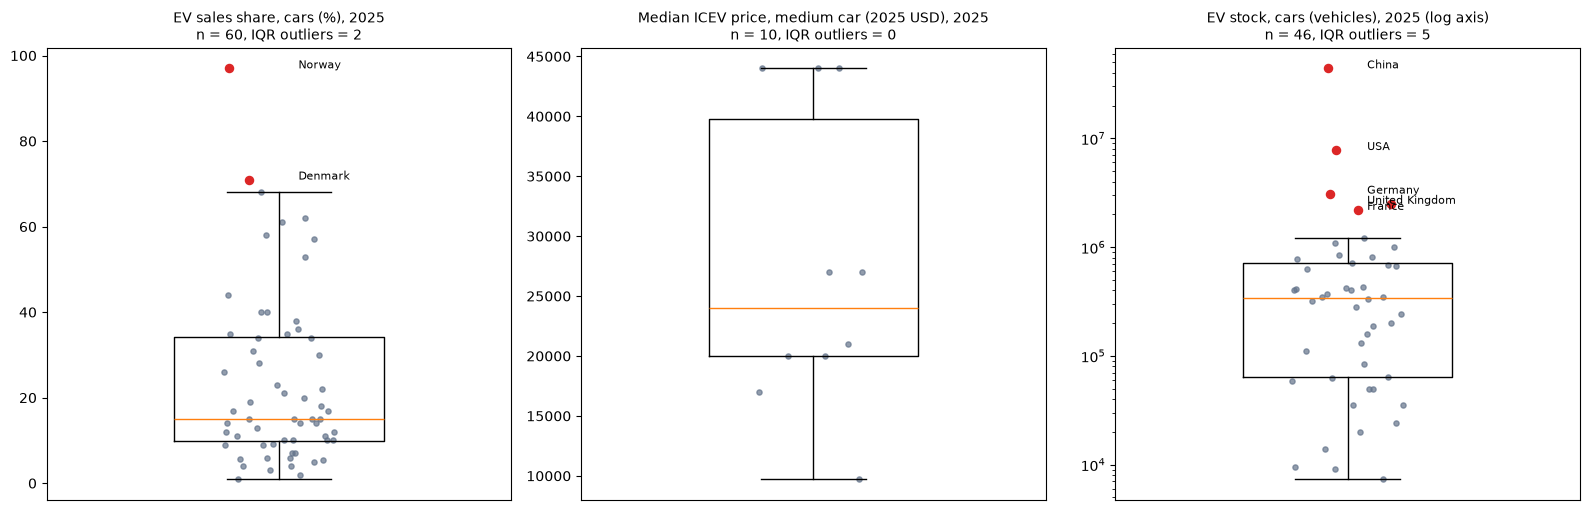

In [5]:
panels = [
    ("Historical", "EV sales share", "Cars", "EV", 2025, False, "EV sales share, cars (%), 2025"),
    ("Historical", "price_p50_2025USD", "Medium car", "ICEV", 2025, False, "Median ICEV price, medium car (2025 USD), 2025"),
    ("Historical", "EV stock", "Cars", "EV", 2025, True, "EV stock, cars (vehicles), 2025 (log axis)"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, (cat, par, mod, pwr, yr, use_log, title) in zip(axes, panels):
    grp = flagged[(flagged["category"] == cat) & (flagged["parameter"] == par) & (flagged["mode"] == mod)
                  & (flagged["powertrain"] == pwr) & (flagged["year"] == yr)]
    ax.boxplot(grp["value"], whis=1.5, showfliers=False, widths=0.45)
    normal, out = grp[~grp["is_outlier"]], grp[grp["is_outlier"]]
    rng = np.random.default_rng(0)
    ax.scatter(1 + rng.uniform(-0.12, 0.12, len(normal)), normal["value"], s=14, color="#64748B", alpha=0.7)
    ax.scatter(1 + rng.uniform(-0.12, 0.12, len(out)), out["value"], s=34, color="#DC2626", zorder=3)
    for _, row in out.iterrows():
        ax.annotate(row["region_country"], (1.0, row["value"]), xytext=(14, 0), textcoords="offset points", fontsize=8)
    if use_log:
        ax.set_yscale("log")
    ax.set_xticks([])
    ax.set_title(f"{title}\nn = {len(grp)}, IQR outliers = {len(out)}", fontsize=10)
plt.tight_layout()
plt.show()

## 5. Two cases examined in the cleaning process

### 5a. The 5,000,000 USD price value (kept in the cleaned dataset)

During cleaning, `price_p100_2025USD` showed a maximum of 5,000,000 USD (USA, 2025, Large car, ICEV). The cell below checks whether this value is a statistical outlier within its comparable group and how it relates to the other price statistics for the same car group.

In [6]:
mask_5m = ((flagged["parameter"] == "price_p100_2025USD") & (flagged["region_country"] == "USA")
           & (flagged["year"] == 2025) & (flagged["mode"] == "Large car") & (flagged["powertrain"] == "ICEV"))
case = flagged[mask_5m].iloc[0]
print(f"Value: {case['value']:,.0f} {case['unit']}  |  group size n = {case['group_n']}")
print(f"Group Q1 = {case['q1']:,.0f}, Q3 = {case['q3']:,.0f}, upper fence = {case['upper_fence']:,.0f}")
print("Flagged as IQR outlier:", bool(case["is_outlier"]))

same_group = flagged[(flagged["parameter"] == "price_p100_2025USD") & (flagged["year"] == 2025)
                     & (flagged["mode"] == "Large car") & (flagged["powertrain"] == "ICEV")]
print("\nAll country values in this group (sorted):")
display(same_group.sort_values("value")[["region_country", "value", "is_outlier"]].reset_index(drop=True))

usa_prices = outlier_df[(outlier_df["region_country"] == "USA") & (outlier_df["year"] == 2025)
                        & (outlier_df["mode"] == "Large car") & (outlier_df["powertrain"] == "ICEV")
                        & outlier_df["parameter"].str.startswith("price_")]
print("\nUSA, 2025, Large car, ICEV - all price statistics:")
display(usa_prices[["parameter", "value", "unit"]].sort_values("value").reset_index(drop=True))

Value: 5,000,000 2025 USD  |  group size n = 10
Group Q1 = 777,500, Q3 = 2,350,000, upper fence = 4,708,750
Flagged as IQR outlier: True

All country values in this group (sorted):


,region_country,value,is_outlier
0,Mexico,2.8e+05,False
1,Indonesia,5e+05,False
2,Malaysia,5.7e+05,False
3,China,1.4e+06,False
4,Brazil,2.1e+06,False
5,Japan,2.1e+06,False
6,Germany,2.2e+06,False
7,Turkiye,2.4e+06,False
8,United Kingdom,3e+06,False
9,USA,5e+06,True



USA, 2025, Large car, ICEV - all price statistics:


,parameter,value,unit
0,price_p0_2025USD,2.7e+04,2025 USD
1,price_p25_2025USD,4.7e+04,2025 USD
2,price_p50_2025USD,6.2e+04,2025 USD
3,price_mean_2025USD,7.8e+04,2025 USD
4,price_p75_2025USD,9.1e+04,2025 USD
5,price_p95_2025USD,1.5e+05,2025 USD
6,price_p100_2025USD,5e+06,2025 USD


**Assessment.** `price_p100` is the *highest observed price* in a vehicle group, so it reflects the most expensive niche models and is expected to be far above the median (here 62,000 USD). In its comparable group (10 countries, Large car ICEV, 2025) the USA value of 5,000,000 USD **is flagged by the IQR rule, but only marginally**: it exceeds the upper fence (about 4.71 million USD) by roughly 6 %, and the next-highest country value is 3,000,000 USD. Several other countries also report `price_p100` values above 2,000,000 USD, so the group is wide and heavy-tailed. The value is therefore **a statistical outlier that is plausible as a luxury/niche-vehicle maximum, not evidence of a data error**, and it was kept in the cleaned data. The dashboard's violin plot references only the **median** price (`price_p50_2025USD`; confirmed by the code check below), so this maximum does not influence that chart.

In [7]:
import re
violin_file = find_file("src/charts/violin.py")
if violin_file is not None:
    text = violin_file.read_text(encoding="utf-8")
    price_params = sorted(set(re.findall(r"price_p[0-9]+_2025USD|price_mean_2025USD", text)))
    print("Price parameters referenced in src/charts/violin.py:", price_params)
else:
    print("src/charts/violin.py not available in this environment (e.g. Colab); check skipped.")

Price parameters referenced in src/charts/violin.py: ['price_p50_2025USD']


### 5b. The five UAE Vans EV sales-share records removed during cleaning

Five `EV sales share` records for the United Arab Emirates (Vans, EV, 2021-2025) were removed because their values (200-310 %) exceed 100 % and are impossible for a share. The raw file is read **read-only** below to test the same records with the IQR rule against all other countries in each year. This is a documentation check; nothing is re-added to or removed from any dataset.

In [8]:
RAW_PATH = find_file("data/EV data by country 2026.xlsx", "EV data by country 2026.xlsx")
if RAW_PATH is not None:
    raw_check = pd.read_excel(RAW_PATH, sheet_name="GEVO_EV_2026")
    raw_source = RAW_PATH.name
elif "df" in globals() and {"parameter", "region_country"} <= set(df.columns):
    raw_check = df.copy()                              # Colab: raw table loaded earlier in the notebook
    raw_source = "in-memory raw df"
else:
    raw_check, raw_source = None, None

if raw_check is None:
    print("Raw IEA Excel file not available here; this case could not be re-checked.")
else:
    print("Raw source:", raw_source, "| shape:", raw_check.shape)
    vans_raw = raw_check[(raw_check["parameter"] == "EV sales share") & (raw_check["mode"] == "Vans")
                         & (raw_check["powertrain"] == "EV") & (raw_check["category"] == "Historical")
                         & (raw_check["region_country"].notna())
                         & raw_check["Aggregate group"].isin(COUNTRY_GROUPS)].copy()
    vans_flagged = flag_iqr(vans_raw, keys=["category", "parameter", "mode", "powertrain", "unit", "year"])
    uae = vans_flagged[vans_flagged["region_country"] == "United Arab Emirates"].sort_values("year")
    display(uae[["year", "value", "group_n", "q3", "upper_fence", "is_outlier"]].reset_index(drop=True))

    others = vans_flagged[vans_flagged["region_country"] != "United Arab Emirates"]
    print("Largest Vans EV sales-share value among all OTHER countries, 2010-2025: "
          f"{others['value'].max():.2f}%")

    in_clean = outlier_df[(outlier_df["region_country"] == "United Arab Emirates")
                          & (outlier_df["parameter"] == "EV sales share") & (outlier_df["mode"] == "Vans")]
    print("UAE Vans EV sales-share years present in the cleaned dataset:", sorted(in_clean["year"].tolist()))

Raw source: EV data by country 2026.xlsx | shape: (49375, 9)


,year,value,group_n,q3,upper_fence,is_outlier
0,2020,5.6,27,2.65,6.182,False
1,2021,200,28,4.15,9.753,True
2,2022,280,28,8.325,19.54,True
3,2023,310,28,13,31.46,True
4,2024,290,29,9.3,21.6,True
5,2025,210,30,15.5,35.38,True


Largest Vans EV sales-share value among all OTHER countries, 2010-2025: 84.00%
UAE Vans EV sales-share years present in the cleaned dataset: [2020]


**Assessment.** In each of 2021-2025 the UAE Vans value lies above the IQR upper fence of its year (2020 does not), and in addition the values are **logically impossible** for a percentage share (> 100 %). The largest Vans EV sales share reported by any other country is 84 %. The domain-rule violation (a share above 100 %), not the IQR result alone, justified removing these five records during cleaning. Note that the statistical test would also have flagged them. The cause (for example a scale or unit problem in the source) cannot be established from the data. The 2020 value (5.6 %) is not impossible and was kept; it was not re-evaluated here because this section does not change any data.

## 6. Why statistical outliers are not deleted automatically

* **IQR flags unusual values, not wrong values.** The rule only says a value is far from the middle of its comparison group.
* **Heavy-tailed data are expected.** EV sales, stock and charging points are strongly right-skewed: China, the USA and a few European markets are legitimately far larger than most countries. Removing them would erase the most important markets and bias every comparison.
* **Large share of flags in count indicators.** Roughly one in seven evaluated vehicle-count values is flagged (Section 2), which shows the rule detects skewness here rather than errors.
* **Small groups.** Many groups contain few countries, so quartiles and fences are unstable.
* **Dashboard design already limits the impact.** The charts use medians (violin), ranks, shares and log scales, and exclude aggregates from country comparisons, so extreme values are shown rather than silently removed.
* **Decision rule used in this project.** A record is removed only when it is *invalid by definition* (e.g. a percentage above 100 %, a missing country, an exact duplicate). Values that are merely extreme are kept, documented, and interpreted with care.

**Limitations of this analysis.** IQR assumes comparable groups of adequate size; 981 of 3,170 groups could not be evaluated (see Section 1). Related rows overlap (for example `All cars` and `ALL` powertrain rows are not independent of the individual segments), so counts of flagged rows are indicative, not independent events. Energy indicators and the 2035 projection rows have no group with at least 8 countries and were not evaluated. Group definitions are a design choice; other groupings would give different counts.

In [9]:
# ---- Integrity check: this section did not change the cleaned data -----------------------
fingerprint_after = int(pd.util.hash_pandas_object(outlier_df, index=True).sum())
print("Rows x columns        :", outlier_df.shape)
print("In-memory data unchanged:", fingerprint_before == fingerprint_after)
if CLEAN_PATH is not None:
    sha_after = hashlib.sha256(CLEAN_PATH.read_bytes()).hexdigest()
    print("File on disk unchanged  :", sha_before == sha_after, "| SHA-256:", sha_after[:16] + "...")
print("Total flagged (analysis only, nothing removed):", int(flagged["is_outlier"].sum()))

Rows x columns        : (48277, 9)
In-memory data unchanged: True
File on disk unchanged  : True | SHA-256: 9bfd8f0ea41f370f...
Total flagged (analysis only, nothing removed): 3235
